# Phi Sgr - 30/08/2025 - Line measures

In [1]:
import math
import os
import random as rnd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.optimize import curve_fit
from scipy.special import voigt_profile
from joblib import Parallel, delayed

import warnings
warnings.filterwarnings('ignore')

## Initial configuration

In [2]:
SPECTRUM_FILE_NAME = "_phisgr_20250830_851.fit"

##########################
# Continuum fitting related constants
##########################

EXCLUDED_REGIONS = [(3720,3725),(3730,3740),(3742,3755),(3762,3778),(3790,3810),(3815,3855),(3870,3910),(3940,4000),(4060,4140),(4300,4380),(4820,4900),(6450,6500),(6515,6600)]

SIGMALO_RANGE=(1.70, 2.2)
SIGMAHI_RANGE=(9.90,10.10)
DEGREE_RANGE = (6,12)

##########################
# Noise evaluation related constants
##########################

NOISE_EVALUATION_WINDOW = (6700,6800)
NOISE_CONTINUUM_WINDOW = (6600,7000)

NOISE_CONTINUUM_DEGREE = 10 # Degree of the polynomial used to fit the continuum in the noise evaluation window

##########################
# Line fitting related constants
##########################

GAUSS_FIT_WINDOW = 3 # in FWHM units
VOIGT_FIT_WINDOW = 3 # in FWHM units

GAUSSIAN_FIT_PLOT_WINDOW = 2.25    # In FWHM units
VOIGT_FIT_PLOT_WINDOW = 4.0        # In FWHM units

#############################
# Lines fit bounds
#############################

GAUSS_LAMBDA_WIN = 3.0  # In angstrom
VOIGT_LAMBDA_WIN = 3.0  # In angstrom

GAUSS_AMP_MIN = -1.5
GAUSS_AMP_MAX = 0.0

GAUSS_SIGMA_MIN = 0.5  # Respect to the expected value (for single lines) or sigma instr (for blended lines)
GAUSS_SIGMA_MAX = 4.0  # Respect to the expected value (for single lines) or sigma instr (for blended lines)

VOIGT_SIGMA_MIN = 0.5  # Respect to the expected value (for single lines) or sigma instr (for blended lines)
VOIGT_SIGMA_MAX = 4.0  # Respect to the expected value (for single lines) or sigma instr (for blended lines)

INSTR_RESOLUTION = 850    # R = lambda/delta_lambda

#############################
# Blend fitting window
#############################

BLEND_SPAN_MARGIN_FACTOR = 1.25  # margin >= factor * (lam_max - lam_min)
BLEND_FWHM_MARGIN = 3.0          # margin >= this * FWHM of the broadest significant component
BLEND_MIN_EW_FRACTION = 0.1      # ignore components with EW < fraction * max EW
BLEND_WINDOW_MAX_ITER = 5
BLEND_WINDOW_TOL = 1.0           # Angstrom
VOIGT_GAMMA_MAX = 4.0            # voigt gamma upper bound, in units of sigma_instr

MONTECARLO_SAMPLES = 2500

ADD_NOISE = True

REMOVE_WORST_FITS = True
WORST_FIT_SIGMA_TO_REMOVE = 0.655 * math.log10(MONTECARLO_SAMPLES) + 1.27  # After this there should be (roughly) less than half an event
#WORST_FIT_PERC_TO_REMOVE = 50

SHOW_PARAM_DEPENDENCIES = False

## List of lines

In [3]:
measuring_lines = [{
    "name": "H alfa",
    "model": "voigt",
    "central_wl": 6563.0,
    "winlo_range":(6300.0,6400.0),
    "winhi_range":(6650.0,6750.0)
    },
                   {
    "name": "H beta",
    "model": "voigt",
    "central_wl": 4861.0,
    "winlo_range":(4500.0,4650.0),
    "winhi_range":(5200.0,5400.0)
    },
#                   {
#    "name": "H delta",
#    "model": "voigt",
#    "central_wl": 4101.0,
#    "winlo_range":(3800.0,3900.0),
#    "winhi_range":(4200.0,4300.0)
#    },
                   {
    "name": "Si II 5056",
    "model": "gauss",
    "central_wl": 5056.0,
    "winlo_range":(4900.0,5000.0),
    "winhi_range":(5100.0,5200.0)
    },
                   {
    "name": "Si II 6347",
    "model": "gauss",
    "central_wl": 6347.0,
    "winlo_range":(6075.0,6200.0),
    "winhi_range":(6475.0,6600.0)
    },
                   {
    "name": "Si II 6371",
    "model": "gauss",
    "central_wl": 6371.0,
    "winlo_range":(6125.0,6250.0),
    "winhi_range":(6450.0,6575.0)
    },
                   {
    "name": "He I 4026",
    "model": "gauss",
    "central_wl": 4026.0,
    "winlo_range":(3775.0,3900.0),
    "winhi_range":(4100.0,4200.0)
    },
                   {
    "name": "He I 4922",
    "model": "gauss",
    "central_wl": 4922.0,
    "winlo_range":(4675.0,4800.0),
    "winhi_range":(5000.0,5125.0)
    }
]

In [4]:
measuring_blends = [{
    "name": "H gamma",
    "central_wls": [{"name": "H gamma",     "wavelength": 4341.0, "model":"voigt"},
                    {"name": "He I 4388",  "wavelength": 4388.0}],
    "winlo_range":(3900.0,4125.0),
    "winhi_range":(4525.0,4675.0)
    },
                    {
    "name": "H delta",
    "central_wls": [{"name": "H delta",        "wavelength": 4101.0, "model":"voigt"},
                    {"name": "Si II 4128-31",  "wavelength": 4130.0},
                    {"name": "He I 4144",      "wavelength": 4144.0}],
    "winlo_range":(3850.0,3950.0),
    "winhi_range":(4275.0,4375.0)
    },
                    {
    "name": "Mg II 4481",
    "central_wls": [{"name": "Mg II 4481",     "wavelength": 4481.0},
                    {"name": "He I 4471",      "wavelength": 4470.0},
                    {"name": "Fe II 4489-91",  "wavelength": 4490.0}],
    "winlo_range":(4100.0,4325.0),
    "winhi_range":(4575.0,4700.0)
    },
                    {
    "name": "Si II 5041",
    "central_wls": [{"name": "Unknown 5032", "wavelength": 5032.0},
                    {"name": "Si II 5041",   "wavelength": 5041.0}],
    "winlo_range":(4900.0,5000.0),
    "winhi_range":(5100.0,5200.0)
    },
                    {
    "name": "He I 4713",
    "central_wls": [{"name": "Unknown 4707",   "wavelength": 4707.0},
                    {"name": "He I 4713",      "wavelength": 4713.0}],
    "winlo_range":(4500.0,4625.0),
    "winhi_range":(4775.0,4900.0)
    }
]

## Load spectrum

In [5]:
def load_spectrum(path):
    with fits.open(path) as hdul:
        hdr = hdul[0].header
        flux = hdul[0].data.astype(float)
        wl = hdr['CRVAL1'] + hdr['CDELT1'] * np.arange(hdr['NAXIS1'])
    good = flux > 0                      # drop the zeroed/bad pixels
    return wl[good], flux[good]

In [6]:
wl, flux = load_spectrum(SPECTRUM_FILE_NAME)

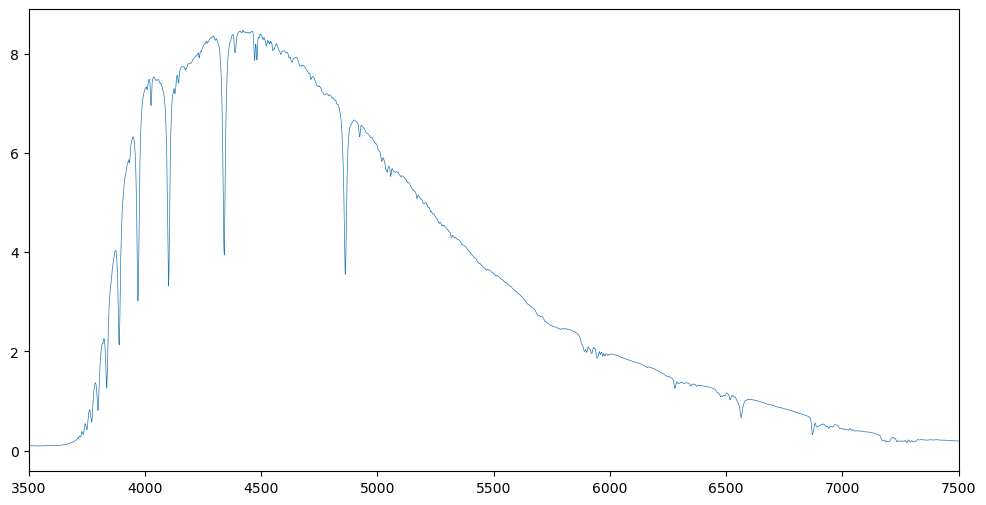

In [7]:
plt.figure(figsize=(12,6))
plt.plot(wl, flux, lw=0.5)
#plt.ylim(ymin, ymax)
plt.xlim(3500,7500)
plt.show()

## Continuum related procedures

In [8]:
def robust_continuum_fit(x, y, exclude_windows, degree, sigma_lo=3.0, sigma_hi=3.0, max_iter=20):
    seed = np.ones(len(x), dtype=bool)
    for lo, hi in exclude_windows:
        seed &= ~((x >= lo) & (x <= hi))
    xc = x - x.mean()
    mask = seed.copy()
    for i in range(max_iter):
        p = np.polyfit(xc[mask], y[mask], degree)
        resid = y - np.polyval(p, xc)
        s = resid[mask].std()
        new_mask = seed & (resid > -sigma_lo * s) & (resid < sigma_hi * s)
        if np.array_equal(new_mask, mask):
            break
        mask = new_mask
    return p, x.mean(), mask

In [9]:
def rectify_zone(wl, flux, zone, plot=False, degree=7, max_iter=20, sigma_lo=1.5, sigma_hi=10.0):
    zone_min, zone_max = zone
    enlarged_zone_min = zone_min - 50
    enlarged_zone_max = zone_max + 50

    mw = (wl >= enlarged_zone_min) & (wl <= enlarged_zone_max)
    p, wlmean, mask = robust_continuum_fit(wl[mw], flux[mw], EXCLUDED_REGIONS, degree, max_iter=max_iter, sigma_lo=sigma_lo, sigma_hi=sigma_hi)
    cont = np.polyval(p, wl - wlmean)[mw]

    if plot:
        plt.figure(figsize=(12,6))
        plt.plot(wl[mw], flux[mw], lw=0.5)
        plt.plot(wl[mw], cont, lw=0.5)
        #plt.ylim(ymin, ymax)
        plt.xlim(enlarged_zone_min,enlarged_zone_max)
        plt.title("Continuum fit")
        plt.show()    

    rect3 = flux[mw] / cont
    wl3 = wl[mw]
    mw = (wl3 >= zone_min) & (wl3 <= zone_max)
    rect3 = rect3[mw]
    wl3 = wl3[mw]  

    if plot:
        plt.figure(figsize=(12,6))
        plt.plot(wl3, rect3, lw=0.5)
        #plt.ylim(0.7, 1.05)
        plt.xlim(enlarged_zone_min,enlarged_zone_max)
        plt.title("Continuum calibrated spectrum")
        plt.show()

    return wl3, rect3

## Noise evaluation

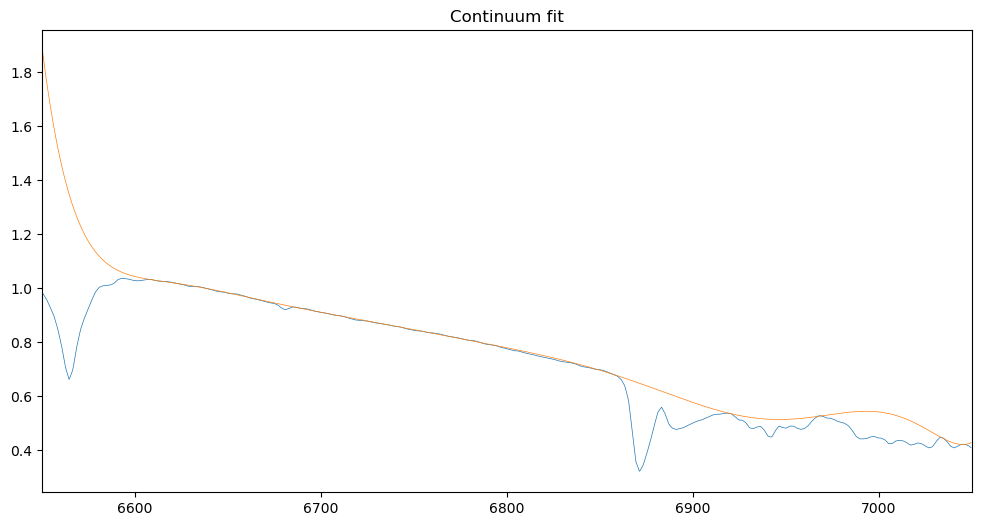

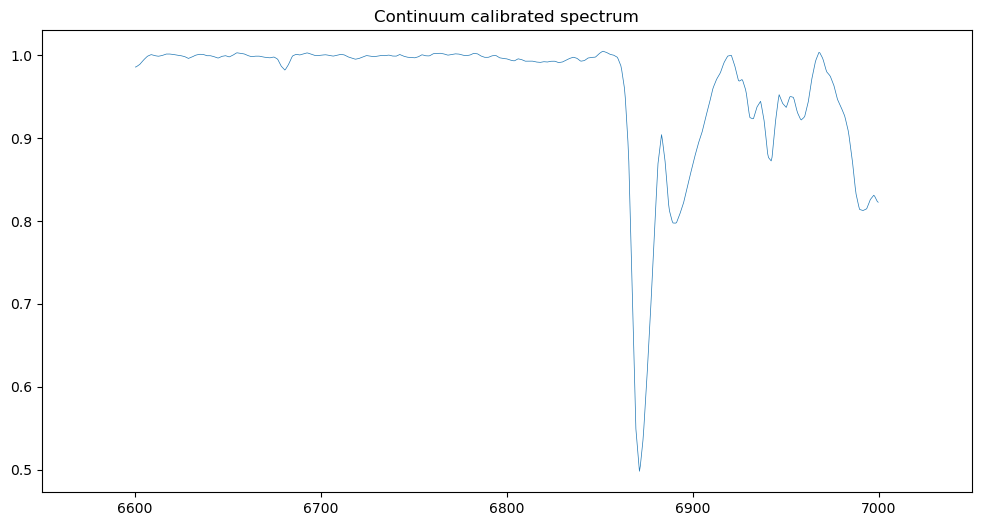

Noise =  0.0015277328064360936 Flux at eval window =  0.8444108963012695 SNR =  552.7215837376154


In [10]:
continuum_mask = (wl > NOISE_CONTINUUM_WINDOW[0]) & (wl < NOISE_CONTINUUM_WINDOW[1])
wlzone, rectzone = rectify_zone(wl, flux, NOISE_CONTINUUM_WINDOW, degree=NOISE_CONTINUUM_DEGREE, plot=True)
evaluation_mask = (wlzone > NOISE_EVALUATION_WINDOW[0]) & (wlzone < NOISE_EVALUATION_WINDOW[1])
noise = 1.4826 * np.median(
        np.abs(rectzone[evaluation_mask] - np.median(rectzone[evaluation_mask]))
    )
noise_evaluation_flux = np.median(flux[continuum_mask][evaluation_mask])
snr = noise_evaluation_flux / noise
print("Noise = ",noise, "Flux at eval window = ", noise_evaluation_flux, "SNR = ", snr)

## Line Fitting procedures

In [11]:
def gaussian_model(x, amp, mu, sigma, offset):
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2) + offset
    
    

def voigt_model(x, amp, mean, sigma, gamma, offset):
    # voigt_profile(x - mean, sigma, gamma) è normalizzata a area = 1
    return amp * voigt_profile(x - mean, sigma, gamma) + offset

In [12]:
def plot_gauss_fit(w, f, popt, name):
    plt.figure(figsize=(6,4))
    plt.plot(w, f, "k", label="Data")
    plt.plot(w, gaussian_model(w, *popt), "r", label="Gaussian fit")
    plt.legend()
    plt.xlabel("Wavelength")
    plt.title(name)
    plt.show()

In [13]:
def calc_gaussian_chi2(w, f, amp, mu, sigma, offset, fwhm):
    wl_min = mu - fwhm
    wl_max = mu + fwhm
    mask = (w > wl_min) & (w < wl_max)
    res_w = w[mask]
    res_f = f[mask]
    return (((res_f - gaussian_model(res_w, amp, mu, sigma, offset)) ** 2)/gaussian_model(res_w, amp, mu, sigma, offset)).sum()

In [14]:
def fit_line_gaussian(wavelength, flux, lam_expected, fwhm_expected, plot=False, name=""):    
    peak_idx = np.argmin(np.abs(wavelength - lam_expected))
    amp0 = max(1.0 - flux[peak_idx], 0.0)
    offset = 1.0
    #p0 = [-amp0, lam_expected, fwhm_expected / 2.355, median_continuum]
    p0 = [-amp0, lam_expected, fwhm_expected / 2.355]
    #if plot:
    #    print("initial guess", p0)
    fit_wl_min = lam_expected - GAUSS_FIT_WINDOW * fwhm_expected
    fit_wl_max = lam_expected + GAUSS_FIT_WINDOW * fwhm_expected
    fit_window_mask = (wavelength > fit_wl_min) & (wavelength < fit_wl_max) 
    w = wavelength[fit_window_mask]
    f = flux[fit_window_mask]
    try:
        # popt, _ = curve_fit(gaussian_model, w, f, p0=p0)
        bounds_lo = [ GAUSS_AMP_MIN * amp0, lam_expected - GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MIN * fwhm_expected / 2.355]
        bounds_hi = [ GAUSS_AMP_MAX * amp0, lam_expected + GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MAX * fwhm_expected / 2.355]
        popt, _ = curve_fit(
            lambda x, a, m, s: gaussian_model(x, a, m, s, offset),
            w,
            f,
            p0 = p0,
            bounds = (bounds_lo, bounds_hi))
        #amp, mu, sigma, offset = popt
        amp, mu, sigma = popt
            
        sigma_nom = abs(sigma)
        fwhm_fit = 2.355 * sigma_nom
        fwhm_nom = fwhm_fit #np.clip(fwhm_fit, 0.7 * fwhm_instr, 1.5 * fwhm_instr)
        ew_nom = np.sqrt(2 * np.pi) * abs(amp) * sigma_nom / offset

        chi2 = calc_gaussian_chi2(w, f, amp, mu, sigma, offset, fwhm_nom)
        
        if plot:
            print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\noffset =",offset,"\nchi2 = ",chi2)
            plot_mask = (w >= mu-GAUSSIAN_FIT_PLOT_WINDOW*fwhm_nom) & (w <= mu+GAUSSIAN_FIT_PLOT_WINDOW*fwhm_nom)
            plot_gauss_fit(w[plot_mask], f[plot_mask], (amp, mu, sigma, offset), name)
    except RuntimeError:
        fwhm_nom = np.nan
        ew_nom = np.nan
        mu = np.nan
        amp = np.nan
        chi2 = np.nan

    return (mu, ew_nom, fwhm_nom, amp, chi2)

In [15]:
def plot_voigt_fit(w, f, popt, name):
    plt.figure(figsize=(6,4))
    plt.plot(w, f, "k", label="Data")
    plt.plot(w, voigt_model(w, *popt), "r", label="Voigt fit")
    plt.legend()
    plt.xlabel("Wavelength")
    plt.title(name)
    plt.show()

In [16]:
def calc_voigt_chi2(w, f, amp, mu, sigma, gam, offset, fwhm):
    wl_min = mu - 2 * fwhm
    wl_max = mu + 2 * fwhm
    mask = (w > wl_min) & (w < wl_max)
    res_w = w[mask]
    res_f = f[mask]
    return (((res_f - voigt_model(res_w, amp, mu, sigma, gam, offset))**2)/voigt_model(res_w, amp, mu, sigma, gam, offset)).sum()

In [17]:
def fit_line_voigt(wavelength, flux, lam_expected, fwhm_expected, plot=False, name=""):
    
    peak_idx = np.argmin(np.abs(wavelength - lam_expected))
    amp0 = max(1.0 - flux[peak_idx], 0.0)
    offset = 1.0
    p0 = [-amp0, lam_expected, fwhm_expected / 2.355, fwhm_expected / 2.355]
    #p0 = [-amp0, lam_expected, fwhm_expected / 2.355, fwhm_expected / 2.355, offset]
    fit_wl_min = lam_expected - VOIGT_FIT_WINDOW * fwhm_expected
    fit_wl_max = lam_expected + VOIGT_FIT_WINDOW * fwhm_expected
    fit_window_mask = (wavelength > fit_wl_min) & (wavelength < fit_wl_max) 
    w = wavelength[fit_window_mask]
    f = flux[fit_window_mask]
    #if plot:
    #    print("initial guess", p0)
    try:
        #popt, _ = curve_fit(voigt_model, w, f, p0=p0)
        popt, _ = curve_fit(
            lambda x, a, m, s, g: voigt_model(x, a, m, s, g, offset),
            w,
            f,
            p0 = p0)
        #amp, mu, sigma, gam, offset = popt
        amp, mu, sigma, gam = popt
        #sigma_nom = abs(sigma)

        intensity = amp * voigt_profile(0.0, sigma, gam)
        
        f_g = 2 * sigma * np.sqrt(2 * np.log(2))
        f_l = 2 * gam
        fwhm_nom = 0.5346 * f_l + np.sqrt(0.2166 * f_l**2 + f_g**2)
        
        ew_nom = abs(amp)/offset

        chi2 = calc_voigt_chi2(w, f, amp, mu, sigma, gam, offset, fwhm_nom)
        
        if plot:
            print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\ngamma =",gam,"\noffset =",offset,"\nchi2 =",chi2)
            plot_mask = (w >= mu-VOIGT_FIT_PLOT_WINDOW*fwhm_nom) & (w <= mu+VOIGT_FIT_PLOT_WINDOW*fwhm_nom)
            plot_voigt_fit(w[plot_mask], f[plot_mask], (amp, mu, sigma, gam, offset), name)
    except RuntimeError:
        fwhm_nom = np.nan
        ew_nom = np.nan
        mu = np.nan
        intensity = np.nan
        chi2 = np.nan

    return (mu, ew_nom, fwhm_nom, intensity, chi2)

In [18]:
# Number of fit parameters used by each component model:
#   gauss : amp (line depth), mu, sigma
#   voigt : amp (area),       mu, sigma, gamma
PARAMS_PER_MODEL = {"gauss": 3, "voigt": 4}


def normalize_model_name(line):
    """Return 'gauss' or 'voigt' for a blend component dict (default: 'gauss')."""
    model = str(line.get("model", "gauss")).strip().lower()
    if model in ("gauss", "gaussian"):
        return "gauss"
    if model == "voigt":
        return "voigt"
    raise ValueError(f"Unknown model '{line.get('model')}' for blend component "
                     f"'{line.get('name')}': use 'gauss' or 'voigt'")


def voigt_fwhm(sigma, gamma):
    # Olivero & Longbothum approximation (same formula used by fit_line_voigt)
    f_g = 2 * sigma * np.sqrt(2 * np.log(2))
    f_l = 2 * gamma
    return 0.5346 * f_l + np.sqrt(0.2166 * f_l**2 + f_g**2)


def component_profile(x, model, params):
    """Profile of a single blend component, WITHOUT the continuum offset."""
    if model == "voigt":
        amp, mu, sigma, gamma = params
        return amp * voigt_profile(x - mu, sigma, gamma)
    amp, mu, sigma = params
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2)


def split_blend_params(models, params):
    """Split the flat parameter vector into one tuple per component."""
    result = []
    k = 0
    for model in models:
        n = PARAMS_PER_MODEL[model]
        result.append(tuple(params[k:k + n]))
        k += n
    return result


def multi_line_model(x, offset, models, *params):
    """Sum of gaussian / voigt components (one entry of `models` per component) + continuum."""
    model = np.zeros_like(x, dtype=float)
    for m, p in zip(models, split_blend_params(models, params)):
        model += component_profile(x, m, p)
    return model + offset

In [19]:
def multi_line_initial_guess(lines, wavelength, flux):
    """Initial guess and bounds for a blend of gaussian / voigt components.

    `lines` is the list of component dicts ("wavelength" and optionally "model").
    """
    p0 = []
    bounds_lo = []
    bounds_hi = []
    for line in lines:
        model = normalize_model_name(line)
        lam0 = line["wavelength"]
        peak_index = np.argmin(np.abs(wavelength - lam0))
        depth0 = min(flux[peak_index] - 1.0, 0.0)
        fwhm_instr = lam0 / INSTR_RESOLUTION
        sigma_instr = fwhm_instr / 2.355

        if model == "gauss":
            p0 += [depth0, lam0, sigma_instr]
            bounds_lo += [GAUSS_AMP_MIN, lam0 - GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MIN * sigma_instr]
            bounds_hi += [GAUSS_AMP_MAX, lam0 + GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MAX * sigma_instr]
        else:
            # Voigt amplitude is the (normalised) area, i.e. -EW for a continuum of 1.
            # Convert the observed depth to an area using the starting profile shape.
            gamma0 = 0.5 * sigma_instr
            amp0 = depth0 / voigt_profile(0.0, sigma_instr, gamma0)
            # Same limits as the gaussian, expressed as areas (depth * width)
            area_scale = np.sqrt(2 * np.pi) * 4.0 * sigma_instr
            amp_lo, amp_hi = -1.5 * area_scale, 0.5 * area_scale
            p0 += [float(np.clip(amp0, amp_lo, amp_hi)), lam0, sigma_instr, gamma0]
            bounds_lo += [amp_lo, lam0 - VOIGT_LAMBDA_WIN, VOIGT_SIGMA_MIN * sigma_instr, 0.0]
            bounds_hi += [amp_hi, lam0 + VOIGT_LAMBDA_WIN, VOIGT_SIGMA_MAX * sigma_instr, VOIGT_GAMMA_MAX * sigma_instr]

    return (p0, bounds_lo, bounds_hi)

In [20]:
def plot_multi_line_fit(w, f, popt, models, component, name):
    """Plot data, total blend fit and the component called `name`.

    `component` is the (model, params) pair of the component to highlight.
    """
    comp_model, comp_params = component
    plt.figure(figsize=(6,4))
    plt.plot(w, f, "k", label="Data")
    plt.plot(w, multi_line_model(w, 1.0, models, *popt), "r", label="Blend fit")
    plt.plot(w, component_profile(w, comp_model, comp_params) + 1.0, "y",
             label=f"{name} ({comp_model})")
    plt.legend()
    plt.xlabel("Wavelength")
    plt.title(name)
    plt.show()

In [21]:
def blend_initial_fwhm(line):
    """FWHM assumed only for the FIRST pass, before any fit exists.
    gauss: instrumental FWHM. voigt: widest profile the fit bounds allow (generous first window)."""
    sigma_instr = line["wavelength"] / INSTR_RESOLUTION / 2.355
    if normalize_model_name(line) == "voigt":
        return voigt_fwhm(VOIGT_SIGMA_MAX * sigma_instr, VOIGT_GAMMA_MAX * sigma_instr)
    return 2.355 * sigma_instr


def blend_fit_window(lines, fwhms, limits=None):
    """margin = max(span margin, BLEND_FWHM_MARGIN * max(fwhms)), applied on both sides of the outermost components."""
    lams = [l["wavelength"] for l in lines]
    lam_min, lam_max = min(lams), max(lams)
    margin = max(BLEND_SPAN_MARGIN_FACTOR * (lam_max - lam_min), BLEND_FWHM_MARGIN * max(fwhms))
    lo, hi = lam_min - margin, lam_max + margin
    if limits is not None:
        lo, hi = max(lo, limits[0]), min(hi, limits[1])
    return lo, hi


def fit_blend_adaptive(wavelength, flux, lines, limits=None):
    """Fit, rebuild the window from the fitted FWHMs, refit until the window is stable.
    Returns (results, window). `limits` = (lo, hi) range that must never be exceeded."""
    window = blend_fit_window(lines, [blend_initial_fwhm(l) for l in lines], limits)
    results = None
    for _ in range(BLEND_WINDOW_MAX_ITER):
        try:
            new_results = fit_blend_group(wavelength, flux, lines, fit_window=window)
        except RuntimeError:
            if results is None:
                raise
            break                      # keep the last window that worked
        results = new_results
        ews = np.array([r[2] for r in results])
        fwhms = np.array([r[3] for r in results])
        significant = ews >= BLEND_MIN_EW_FRACTION * ews.max()
        new_window = blend_fit_window(lines, fwhms[significant], limits)
        converged = max(abs(new_window[0] - window[0]), abs(new_window[1] - window[1])) < BLEND_WINDOW_TOL
        window = new_window
        if converged:
            break
    return results, window

In [22]:
def fit_blend_group(wavelength, flux, lines, plot=False, fit_window=None):
    models = [normalize_model_name(l) for l in lines]
    if fit_window is None:   # fallback when called without a precomputed window
        fit_window = blend_fit_window(lines, [blend_initial_fwhm(l) for l in lines])
    wl_min, wl_max = fit_window
    
    mask = (wavelength > wl_min) & (wavelength < wl_max)
    
    w = wavelength[mask]
    f = flux[mask]
    offset = 1.0
    
    p0, bounds_lo, bounds_hi = multi_line_initial_guess(lines, w, f)
    
    popt, _ = curve_fit(
            lambda x, *params: multi_line_model(x, offset, models, *params),
            w,
            f,
            p0 = p0,
            bounds = (bounds_lo, bounds_hi))
    
    # One parameter tuple per component (3 values for gauss, 4 for voigt)
    component_results = split_blend_params(models, popt)

    chi2 = (((multi_line_model(w, offset, models, *popt) - f) ** 2)/multi_line_model(w, offset, models, *popt)).sum()
    
    final_results = []
    
    for line, model, params in zip(lines, models, component_results):
        if model == "voigt":
            amp, mu, sigma, gam = params
            fwhm_nom = voigt_fwhm(sigma, gam)
            ew_nom = abs(amp) / offset
            intensity = amp * voigt_profile(0.0, sigma, gam)
        else:
            amp, mu, sigma = params
            fwhm_nom = 2.355 * abs(sigma)
            ew_nom = np.sqrt(2 * np.pi) * abs(amp) * abs(sigma) / offset
            intensity = amp
        
        final_results.append((line["name"], mu, ew_nom, fwhm_nom, intensity, chi2))
        
        if plot:
            print(line["name"], f"({model})")
            if model == "voigt":
                print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\ngamma =",gam,"\noffset =",offset,"\nchi2 =",chi2)
            else:
                print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\noffset =",offset,"\nchi2 =",chi2)
            plot_multi_line_fit(w, f, popt, models, (model, params), line["name"])
        
    return final_results

## Functions for error on continuum placement

In [23]:
# ---------------------------------------------------------------- configuration
N_JOBS  = max(1, (os.cpu_count() or 2) - 2)   # worker processes; leave 2 logical CPUs free
MC_SEED = None                                 # set e.g. to 12345 for reproducible Monte Carlo runs


# ---------------------------------------------------------------- helpers
def _draw_trials(rng, n, sigma_lo_range, sigma_hi_range, degree_range, maxiter_range, winlo_range, winhi_range):
    """Draw all the random continuum parameters up front (same distributions as before)."""
    trials = []
    for i in range(1, n):                       # same count as the original loop
        trials.append(dict(
            i=i,
            sigma_lo=float(rng.uniform(*sigma_lo_range)),
            sigma_hi=float(rng.uniform(*sigma_hi_range)),
            degree=int(rng.integers(*degree_range)),
            maxiter=int(rng.integers(*maxiter_range)),
            win_lo=float(rng.uniform(*winlo_range)),
            win_hi=float(rng.uniform(*winhi_range)),
            seed=int(rng.integers(0, 2**63 - 1)),   # private seed for this trial's noise
        ))
    return trials


def _rectify_trial(wl, flux, t, add_noise, noise, noise_evaluation_flux):
    win = (t["win_lo"], t["win_hi"])
    if add_noise:
        win_mask = (wl > win[0]) & (wl < win[1])
        rescaled_noise = noise * np.sqrt(np.median(flux[win_mask]) * noise_evaluation_flux)
        flux = flux + np.random.default_rng(t["seed"]).normal(0, rescaled_noise, size=len(flux))
    return rectify_zone(wl, flux, win, plot=False, sigma_lo=t["sigma_lo"], sigma_hi=t["sigma_hi"],
                        degree=t["degree"], max_iter=t["maxiter"])


def _run_parallel(chunk_worker, trials, **common):
    """Split the trials in chunks (so the spectrum is shipped once per chunk, not once per trial),
    run them on N_JOBS processes, and return (records, errors)."""
    if N_JOBS == 1:
        outs = [chunk_worker(trials, **common)]
    else:
        n_chunks = min(len(trials), N_JOBS * 4)          # a few chunks per worker -> good load balancing
        chunks = [list(c) for c in np.array_split(np.array(trials, dtype=object), n_chunks)]
        outs = Parallel(n_jobs=N_JOBS)(delayed(chunk_worker)(c, **common) for c in chunks)
    records = [r for o in outs for r in o[0]]
    errors  = [e for o in outs for e in o[1]]
    if errors:
        print(f"{len(errors)} trials failed; first error: {errors[0]}")
    return records, errors

In [24]:
def _single_line_chunk(trials, wl, flux, model, expected_lam, expected_width, add_noise, noise, noise_evaluation_flux):
    records, errors = [], []
    for t in trials:
        try:
            wlzone, rectzone = _rectify_trial(wl, flux, t, add_noise, noise, noise_evaluation_flux)
            if model == "voigt":
                lam, ew, fwhm, amp, chi2 = fit_line_voigt(wlzone, rectzone, expected_lam, expected_width, plot=False)
            else:
                lam, ew, fwhm, amp, chi2 = fit_line_gaussian(wlzone, rectzone, expected_lam, expected_width, plot=False)
            records.append({"sigma_lo": t["sigma_lo"], "sigma_hi": t["sigma_hi"], "degree": t["degree"],
                            "maxiter": t["maxiter"], "win_lo": t["win_lo"], "win_hi": t["win_hi"],
                            "wavelength": lam, "ew": ew, "fwhm": fwhm, "intensity": amp, "chi2": chi2})
        except Exception as e:
            errors.append(repr(e))
    return records, errors

def remove_worst_fits_from_results(results):
    removed = 100
    while removed > 0:
        m_res = results["chi2"].mean()
        s_res = results["chi2"].std()
        filtered_results = results[(results["chi2"]-m_res).abs() <= WORST_FIT_SIGMA_TO_REMOVE*s_res]
        removed = len(results) - len(filtered_results)
        # print(f"Removed {removed}")
        results = filtered_results
    return results

def fit_varying_continuum(wl, flux, model, expected_lam, expected_width, add_noise=False, noise=0.0, noise_evaluation_flux=1.0, sigma_lo_range=(1.5,2.0), sigma_hi_range=(9.9,10.1), degree_range=(6,14), maxiter_range=(10,30), winlo_range=None, winhi_range=None):
    rng = np.random.default_rng(MC_SEED)
    trials = _draw_trials(rng, MONTECARLO_SAMPLES, sigma_lo_range, sigma_hi_range, degree_range, maxiter_range, winlo_range, winhi_range)
    records, _ = _run_parallel(_single_line_chunk, trials, wl=wl, flux=flux, model=model,
                               expected_lam=expected_lam, expected_width=expected_width,
                               add_noise=add_noise, noise=noise, noise_evaluation_flux=noise_evaluation_flux)
    cols = ["sigma_lo","sigma_hi","degree","maxiter","win_lo","win_hi","wavelength","ew","fwhm","intensity","chi2"]
    results = pd.DataFrame(records, columns=cols)

    if REMOVE_WORST_FITS:
        results = remove_worst_fits_from_results(results)

    m = results["ew"].mean()
    results["ew_dist"] = abs(results["ew"] - m)
    
    return results

In [25]:
def refit_with_best(column, results, wl, flux, model, expected_lam, expected_width, plot=False, name=""):
    sort_col = column + "_dist"
    sorted_results = results.sort_values(by=[sort_col], ascending=True)
    best = sorted_results.iloc[0]
    sigma_lo = best["sigma_lo"]
    sigma_hi = best["sigma_hi"]
    degree = int(best["degree"])
    maxiter = int(best["maxiter"])
    win = (best["win_lo"], best["win_hi"])
    wlzone, rectzone = rectify_zone(wl, flux, win, plot=plot, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
    if (model == "voigt"):
        lam, ew, fwhm, amp, chi2 = fit_line_voigt(wlzone, rectzone, expected_lam, expected_width, plot=plot, name=name)
    else:
        lam, ew, fwhm, amp, chi2 = fit_line_gaussian(wlzone, rectzone, expected_lam, expected_width, plot=plot, name=name)
    return (lam, ew, fwhm, amp)

In [26]:
def _blend_chunk(trials, wl, flux, blended_lines, fit_window, add_noise, noise, noise_evaluation_flux):
    records, errors = [], []
    for t in trials:
        try:
            wlzone, rectzone = _rectify_trial(wl, flux, t, add_noise, noise, noise_evaluation_flux)
            blend_results = fit_blend_group(wlzone, rectzone, blended_lines, plot=False, fit_window=fit_window)
            for name, lam_detected, ew, fwhm, amp, chi2 in blend_results:
                records.append({"sigma_lo": t["sigma_lo"], "sigma_hi": t["sigma_hi"], "degree": t["degree"],
                                "maxiter": t["maxiter"], "win_lo": t["win_lo"], "win_hi": t["win_hi"],
                                "record": t["i"], "line": name, "wavelength": lam_detected, "ew": ew,
                                "fwhm": fwhm, "intensity": amp, "chi2": chi2})
        except Exception as e:
            errors.append(repr(e))
    return records, errors


def fit_blend_varying_continuum(wl, flux, blended_lines, add_noise=False, noise=0.0, noise_evaluation_flux=1.0, sigma_lo_range=(1.5,2.0), sigma_hi_range=(9.9,10.1), degree_range=(6,14), maxiter_range=(10,30), winlo_range=None, winhi_range=None, fit_window=None):
    rng = np.random.default_rng(MC_SEED)
    trials = _draw_trials(rng, MONTECARLO_SAMPLES, sigma_lo_range, sigma_hi_range, degree_range, maxiter_range, winlo_range, winhi_range)
    records, _ = _run_parallel(_blend_chunk, trials, wl=wl, flux=flux, blended_lines=blended_lines,
                               fit_window=fit_window, add_noise=add_noise, noise=noise,
                               noise_evaluation_flux=noise_evaluation_flux)
    cols = ["sigma_lo","sigma_hi","degree","maxiter","win_lo","win_hi","record","line","wavelength","ew","fwhm","intensity","chi2"]
    results = pd.DataFrame(records, columns=cols)

    if REMOVE_WORST_FITS:
        results = remove_worst_fits_from_results(results)

    results["ew_dist"] = (results["ew"] - results.groupby("line")["ew"].transform("mean")).abs()
    results["ew_dist_ssq"] = (results["ew_dist"]**2).groupby(results["record"]).transform("sum")

    return results

In [27]:
def refit_blend_with_best(column, results, wl, flux, blended_lines, expected_width, plot=False, name="", fit_window=None):
    sort_col = column + "_dist_ssq"
    sorted_results = results.sort_values(by=[sort_col], ascending=True)
    best = sorted_results.iloc[0]
    sigma_lo = best["sigma_lo"]
    sigma_hi = best["sigma_hi"]
    degree = int(best["degree"])
    maxiter = int(best["maxiter"])
    win = (best["win_lo"], best["win_hi"])
    wlzone, rectzone = rectify_zone(wl, flux, win, plot=True, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
    blend_results = fit_blend_group(wlzone, rectzone, blended_lines, plot=True, fit_window=fit_window)

## Complete measure procedures

In [28]:
def round_measurement(value, error):
    exponent = math.floor(math.log10(error))
    first_digit = int(error / (10 ** exponent))

    sig_figs = 2 if first_digit in (1,2) else 1

    decimals = sig_figs - exponent - 1

    value_rounded = round (value, decimals)
    error_rounded = round(error, decimals)

    return value_rounded, error_rounded

In [29]:
from IPython.display import Markdown
from IPython.display import display

def measure_line(wl, flux, measuring_line, show_param_dependencies=False):
    name = measuring_line["name"]
    
    display(Markdown(f"### Measuring {name}"))
    model = measuring_line["model"]
    central_wl = measuring_line["central_wl"]
    winlo_range = measuring_line["winlo_range"]
    winhi_range = measuring_line["winhi_range"]
    
    display(Markdown(f"#### {name} preliminary fit"))
    rect_win = (winlo_range[1], winhi_range[0])
    wlzone, rectzone = rectify_zone(wl, flux, rect_win, plot=True)
    if model == "voigt":
        lam, ew, fwhm, amp, chi2 = fit_line_voigt(wlzone, rectzone, central_wl, 5.0, plot=True, name=name)
    else:
        lam, ew, fwhm, amp, chi2 = fit_line_gaussian(wlzone, rectzone, central_wl, 5.0, plot=True, name=name)
    print("Lambda = ", lam, "Eq Width =", ew, "FWHM = ", fwhm, "Intensity = ", amp)
    
    display(Markdown(f"#### {name} optimization"))
    results = fit_varying_continuum(wl, flux, model, central_wl, fwhm, winlo_range=winlo_range, winhi_range=winhi_range, degree_range=DEGREE_RANGE, sigma_lo_range=SIGMALO_RANGE, sigma_hi_range=SIGMAHI_RANGE, add_noise=ADD_NOISE, noise=noise, noise_evaluation_flux=noise_evaluation_flux)

    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12,6))
    plt.subplots_adjust(wspace=0.5, hspace=0.5)
    
    m_ew = results["ew"].mean()
    s_ew = results["ew"].std()
    results.plot.hist(column=["ew"], title="EW mean=%g std dev=%g" % round_measurement(m_ew,s_ew), ax=axes[0,0])
    
    m_fwhm = results["fwhm"].mean()
    s_fwhm = results["fwhm"].std()
    results.plot.hist(column=["fwhm"], title="FWHM mean=%g std dev=%g" % round_measurement(m_fwhm,s_fwhm), ax=axes[0,1])
    
    m_wl = results["wavelength"].mean()
    s_wl = results["wavelength"].std()
    results.plot.hist(column=["wavelength"], title="Central wavelength mean=%g std dev=%g" % round_measurement(m_wl,s_wl), ax=axes[1,0])
    
    m_amp = results["intensity"].mean()
    s_amp = results["intensity"].std()
    results.plot.hist(column=["intensity"], title="Intensity mean=%g std dev=%g" % round_measurement(m_amp,s_amp), ax=axes[1,1])
    
    plt.show()

    display(Markdown(f"#### {name} re-fit with best parameters"))
    lam, ew, fwhm, amp = refit_with_best("ew", results, wl, flux, model, central_wl, m_fwhm, plot=True, name=name)
    print("Lambda = ", lam, "Eq Width =", ew, "FWHM = ", fwhm, "Intensity = ", amp)

    if show_param_dependencies:
        display(Markdown(f"#### {name} continuum parameters dependencies"))
        results["win_size"] = results["win_hi"] - results["win_lo"]
        results["dist"] = abs(results["ew"] - m_ew)

        results.plot.hist(column=["chi2"], figsize=(12,6), title="Chi quadro")
        
        sorted_results = results.sort_values(by=["dist"], ascending=True)
        sorted_results.plot(x="dist", y="sigma_lo", ylim=(0,6))
        sorted_results.plot(x="dist", y="degree", ylim=(2,15))
        sorted_results.plot(x="dist", y="maxiter", ylim=(8,32))
        sorted_results.plot(x="dist", y="win_size", ylim=(400,800))
        
        results.sort_values(by=["sigma_lo"], ascending=True).plot(x="sigma_lo", y="dist", ylim=(0,8))
        results.sort_values(by=["win_size"], ascending=True).plot(x="win_size", y="dist", ylim=(0,8))
        
        sorted_results.plot.scatter(x="degree", y="win_size", c="dist")
        sorted_results.plot.scatter(x="win_lo", y="win_hi", c="dist")
        plt.show()
    
    return pd.Series({"line_name":name, "wavelength":m_wl, "delta_wavelength":s_wl, "ew":m_ew, "delta_ew":s_ew, "fwhm":m_fwhm, "delta_fwhm":s_fwhm, "intensity": m_amp, "delta_intensity": s_amp})

In [30]:
def measure_blend(wl, flux, measuring_blend, show_param_dependencies=False):
    name = measuring_blend["name"]
    
    display(Markdown(f"### Measuring {name}"))
    blended_lines = measuring_blend["central_wls"]
    winlo_range = measuring_blend["winlo_range"]
    winhi_range = measuring_blend["winhi_range"]
    print("Blended lines=", blended_lines)
    display(Markdown(f"#### {name} preliminary fit"))
    rect_win = (winlo_range[1], winhi_range[0])
    wlzone, rectzone = rectify_zone(wl, flux, rect_win, plot=True)
    prelim_results, fit_window = fit_blend_adaptive(wlzone, rectzone, blended_lines, limits=rect_win)
    print("Fit window = (%.1f, %.1f)" % fit_window)
    fit_blend_group(wlzone, rectzone, blended_lines, plot=True, fit_window=fit_window)
    
    display(Markdown(f"#### {name} optimization"))
    results = fit_blend_varying_continuum(wl, flux, blended_lines, degree_range=DEGREE_RANGE, sigma_lo_range=SIGMALO_RANGE, sigma_hi_range=SIGMAHI_RANGE, add_noise=ADD_NOISE, noise=noise, noise_evaluation_flux=noise_evaluation_flux, winlo_range=winlo_range, winhi_range=winhi_range, fit_window=fit_window)

    blend_results = pd.DataFrame(columns=("line_name","wavelength","delta_wavelength","ew","delta_ew","fwhm","delta_fwhm","intensity","delta_intensity"))
    i = 0
    for line in blended_lines:
        line_name = line["name"]
        display(Markdown(f"#### Plotting results for {line_name}"))
        line_results = results[results["line"] == line["name"]]

        fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12,6))
        plt.subplots_adjust(wspace=0.5, hspace=0.5)
        
        m_ew = line_results["ew"].mean()
        s_ew = line_results["ew"].std()
        line_results.plot.hist(column=["ew"], figsize=(12,6), title="EW mean=%g std dev=%g" % round_measurement(m_ew,s_ew), ax=axes[0,0])
    
        m_fwhm = line_results["fwhm"].mean()
        s_fwhm = line_results["fwhm"].std()
        line_results.plot.hist(column=["fwhm"], figsize=(12,6), title="FWHM mean=%g std dev=%g" % round_measurement(m_fwhm,s_fwhm), ax=axes[0,1])
        
        m_wl = line_results["wavelength"].mean()
        s_wl = line_results["wavelength"].std()
        line_results.plot.hist(column=["wavelength"], figsize=(12,6), title="Central wavelength mean=%g std dev=%g" % round_measurement(m_wl,s_wl), ax=axes[1,0])

        m_amp = line_results["intensity"].mean()
        s_amp = line_results["intensity"].std()
        line_results.plot.hist(column=["intensity"], figsize=(12,6), title="Intensity mean=%g std dev=%g" % round_measurement(m_amp,s_amp), ax=axes[1,1])
        plt.show()
    
        # print("Mean:", m_ew)
        # print("Std Dev:",s_ew)

        line_results = pd.Series({"line_name":line_name, "wavelength":m_wl, "delta_wavelength":s_wl, "ew":m_ew, "delta_ew":s_ew, "fwhm":m_fwhm, "delta_fwhm":s_fwhm, "intensity":m_amp, "delta_intensity":s_amp})
        blend_results.loc[i] = line_results
        i = i + 1

    display(Markdown(f"#### {name} re-fit with best parameters"))
    refit_blend_with_best("ew", results, wl, flux, blended_lines, m_fwhm, plot=True, name=name, fit_window=fit_window)

    if show_param_dependencies:
        display(Markdown(f"#### {name} continuum parameters dependencies"))

        results.plot.hist(column=["chi2"], figsize=(12,6), title="Chi quadro")
        
        for line in blended_lines:
            print("Plotting results for ",line["name"])
            line_results = results[results["line"] == line["name"]]
        
            m = line_results["ew"].mean()
            
            line_results["win_size"] = line_results["win_hi"] - line_results["win_lo"]
            line_results["dist"] = abs(line_results["ew"] - m)
            
            sorted_results = line_results.sort_values(by=["dist"], ascending=True)
            sorted_results.plot(x="dist", y="sigma_lo", ylim=(0,6))
            sorted_results.plot(x="dist", y="degree", ylim=(2,15))
            sorted_results.plot(x="dist", y="maxiter", ylim=(8,32))
            sorted_results.plot(x="dist", y="win_size", ylim=(250,800))
            
            line_results.sort_values(by=["sigma_lo"], ascending=True).plot(x="sigma_lo", y="dist", ylim=(0,8))
            line_results.sort_values(by=["win_size"], ascending=True).plot(x="win_size", y="dist", ylim=(0,8))
            
            sorted_results.plot.scatter(x="degree", y="win_size", c="dist")
            sorted_results.plot.scatter(x="win_lo", y="win_hi", c="dist")
            plt.show()
            
    return blend_results

## Measure All Lines

### Measuring H alfa

#### H alfa preliminary fit

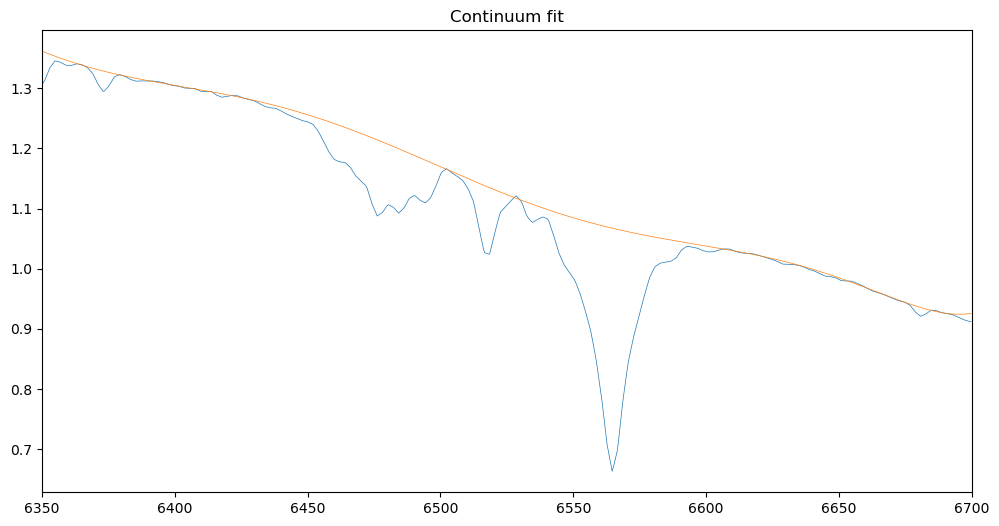

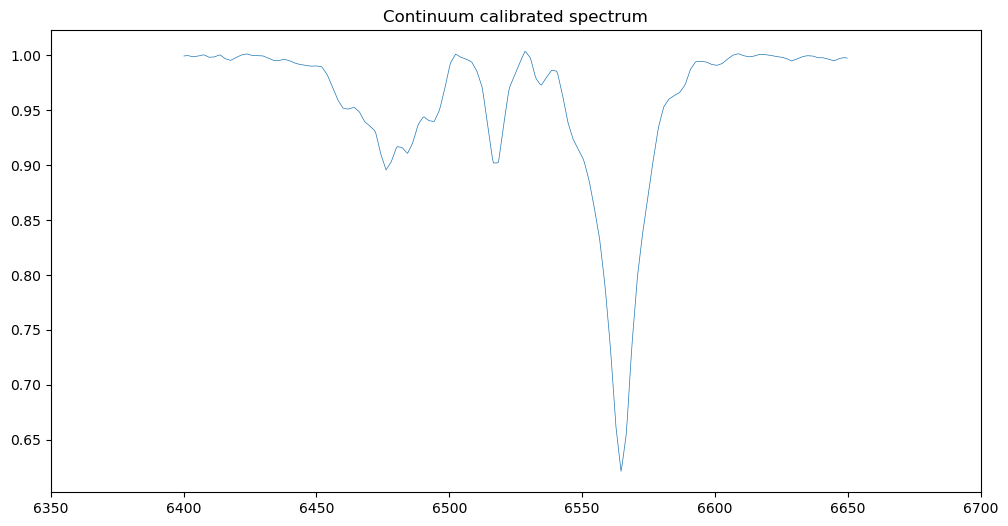

amp = -8.479554787635852 
mu = 6564.5375166068325 
sigma = 3.995565023171693e-05 
gamma = 7.523740905935849 
offset = 1.0 
chi2 = 0.008255386754139313


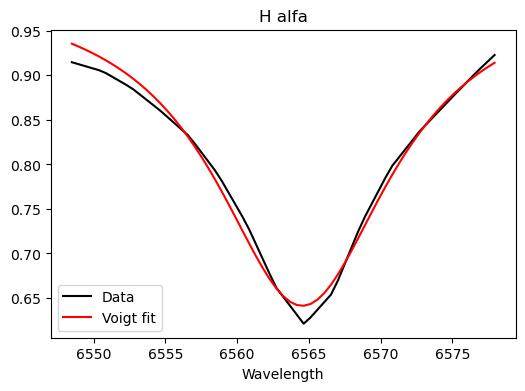

Lambda =  6564.5375166068325 Eq Width = 8.479554787635852 FWHM =  15.047527724308926 Intensity =  -0.3587478826039836


#### H alfa optimization

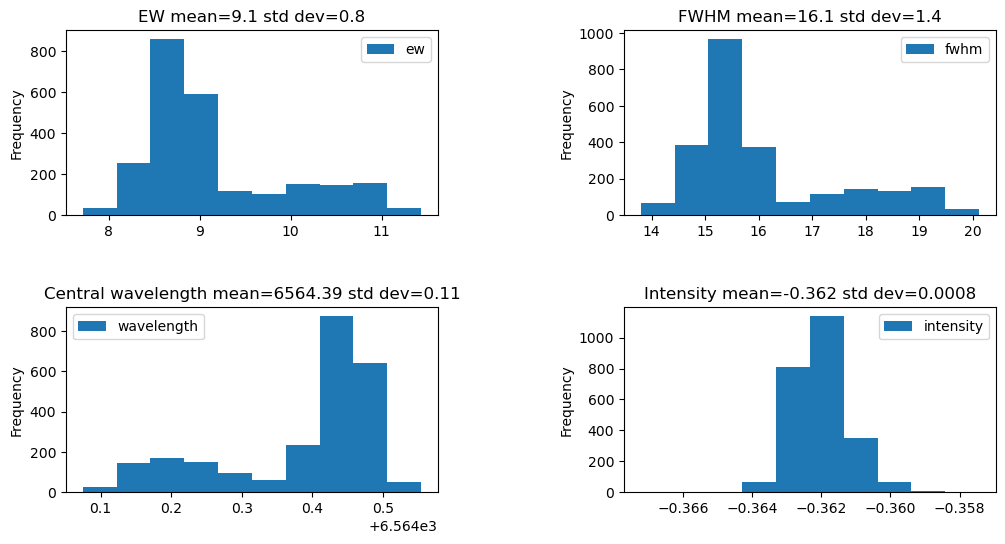

#### H alfa re-fit with best parameters

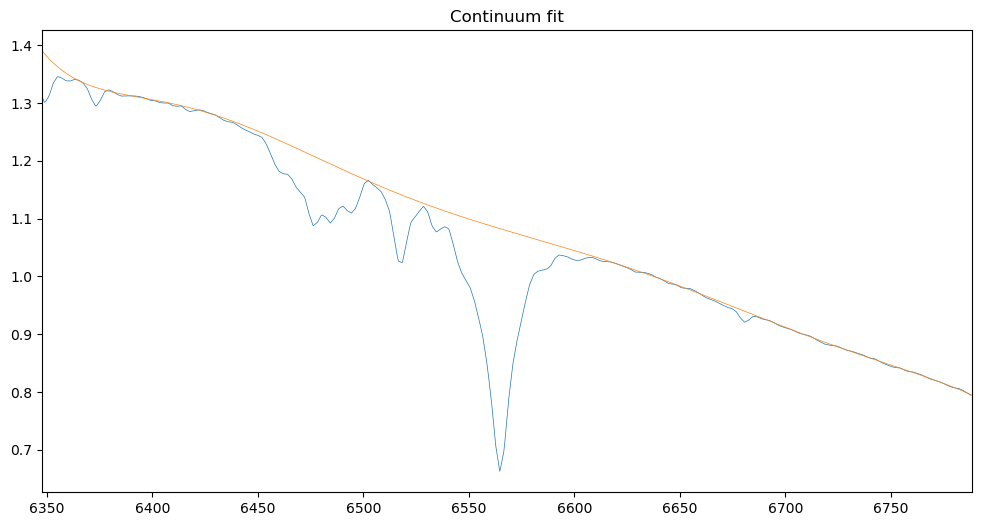

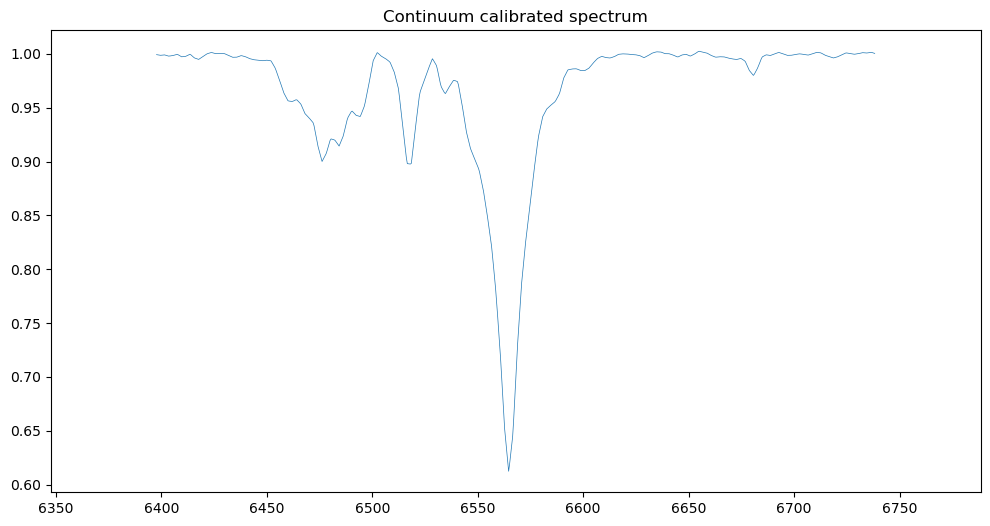

amp = -9.2847662004481 
mu = 6564.399127569008 
sigma = 0.0009109520816409113 
gamma = 8.167755664255633 
offset = 1.0 
chi2 = 0.022543275818474824


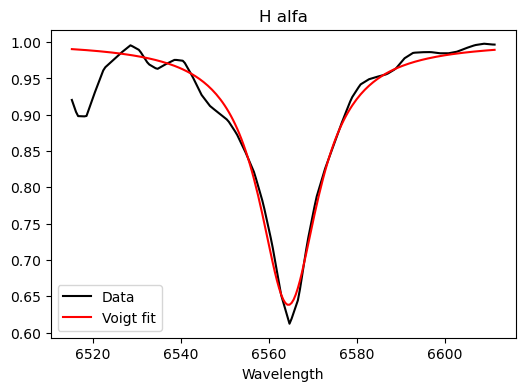

Lambda =  6564.399127569008 Eq Width = 9.2847662004481 FWHM =  16.3355614728922 Intensity =  -0.3618414846417233


### Measuring H beta

#### H beta preliminary fit

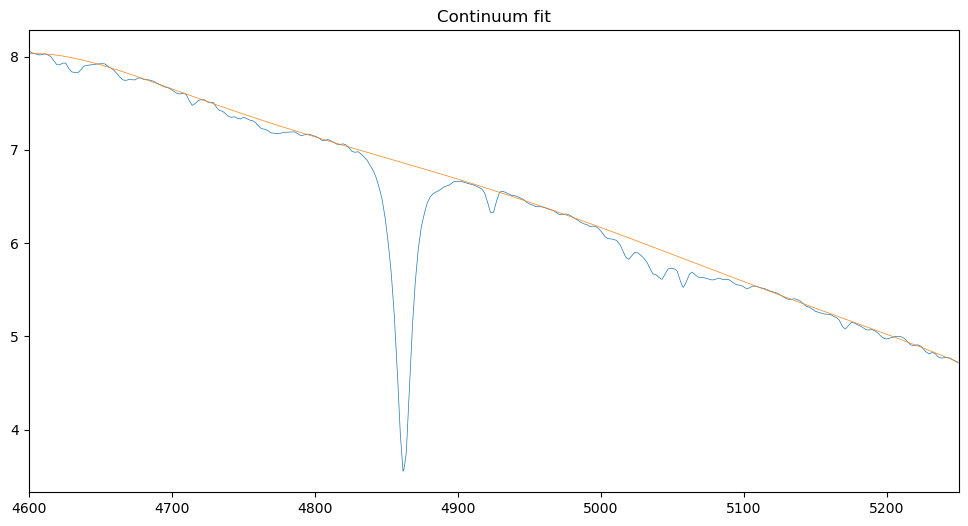

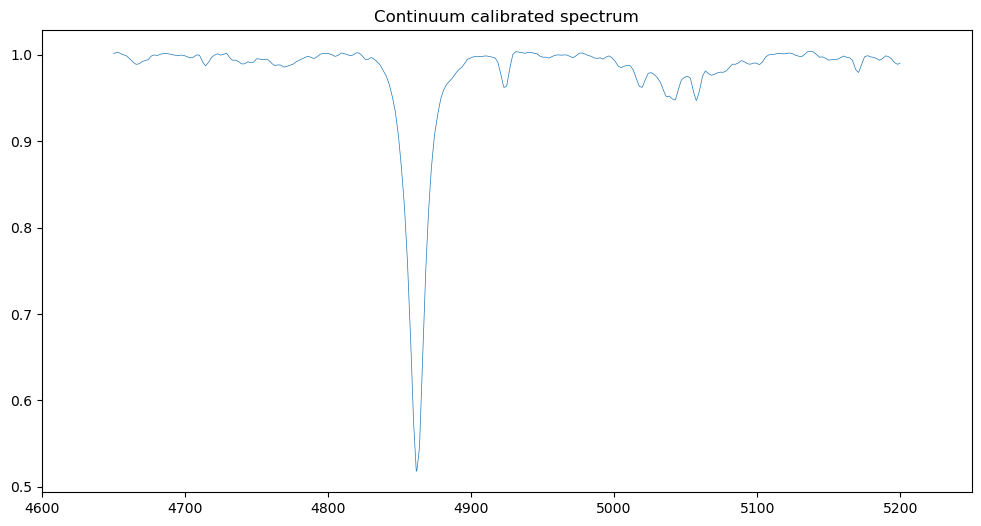

amp = -9.545169344224242 
mu = 4862.096117029574 
sigma = 1.5503228092349786 
gamma = 6.012849981501509 
offset = 1.0 
chi2 = 0.0017565038989319744


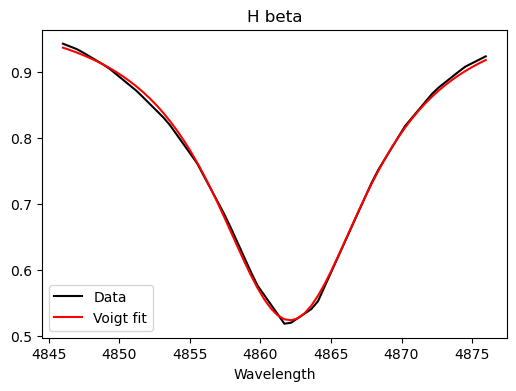

Lambda =  4862.096117029574 Eq Width = 9.545169344224242 FWHM =  13.111152923570412 Intensity =  -0.47685246993238545


#### H beta optimization

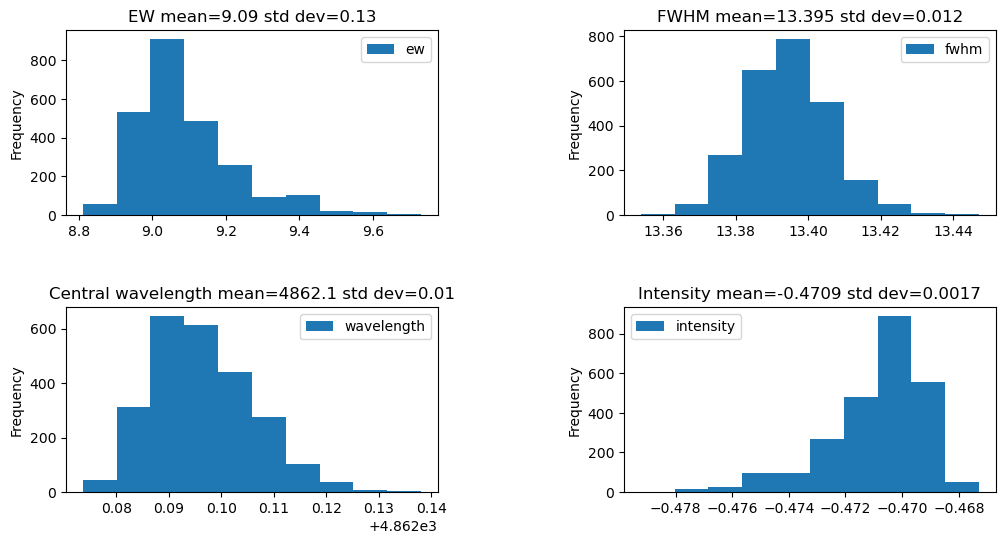

#### H beta re-fit with best parameters

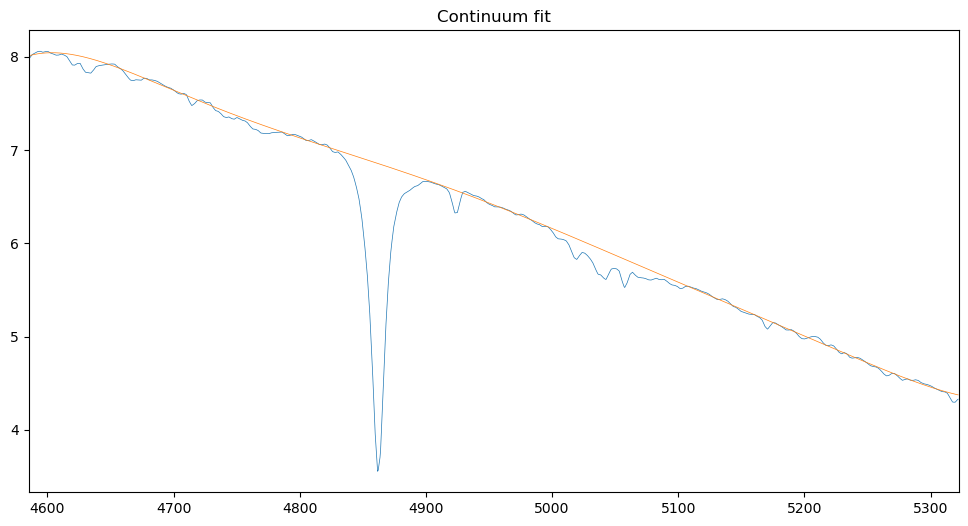

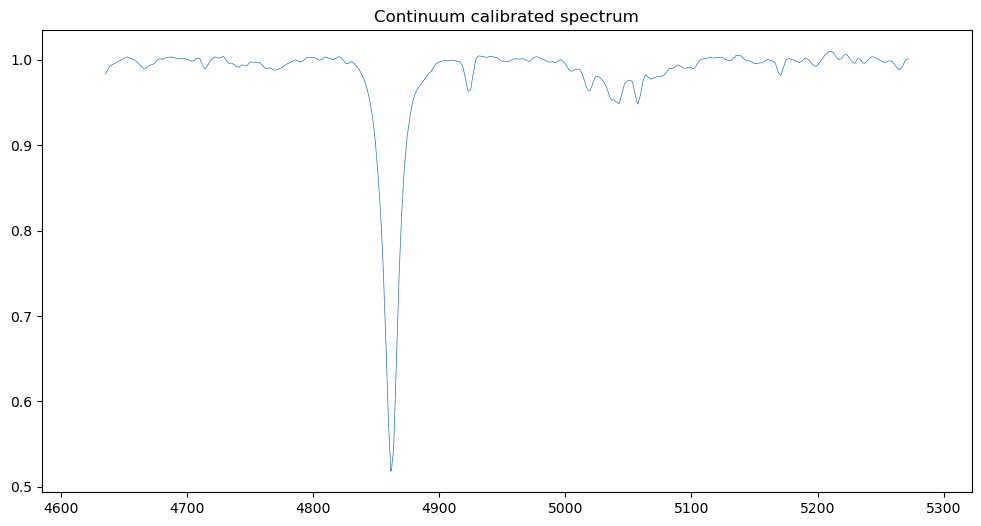

amp = -9.063257843651453 
mu = 4862.096378811135 
sigma = 2.7475387324841325 
gamma = 5.053005609243328 
offset = 1.0 
chi2 = 0.005502083917603901


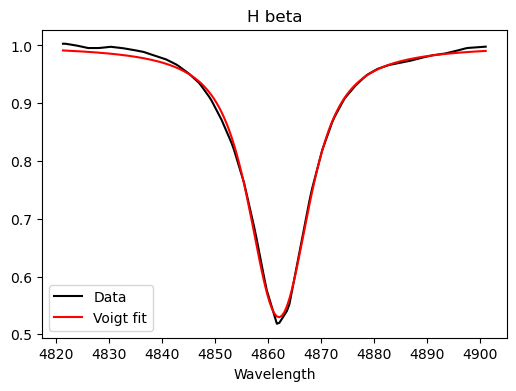

Lambda =  4862.096378811135 Eq Width = 9.063257843651453 FWHM =  13.401551514885613 Intensity =  -0.47053657892421463


### Measuring Si II 5056

#### Si II 5056 preliminary fit

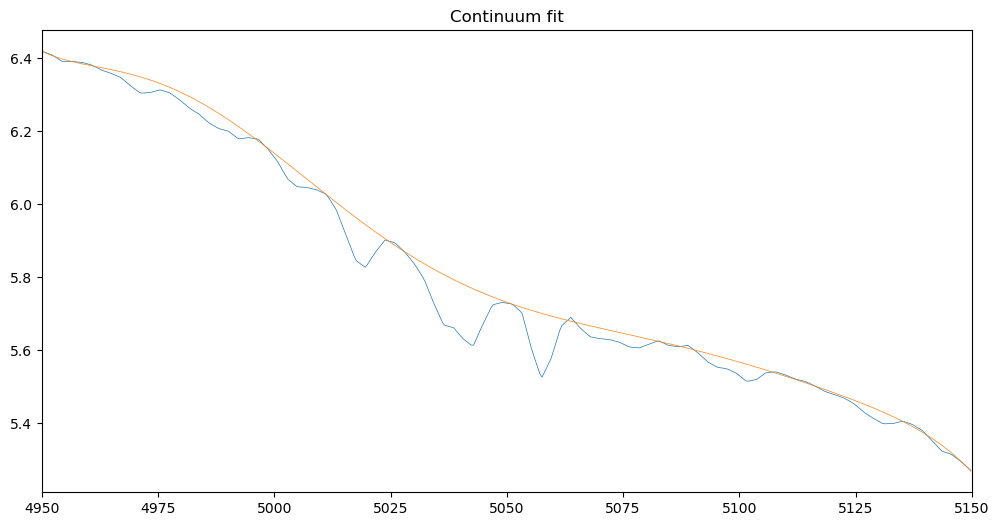

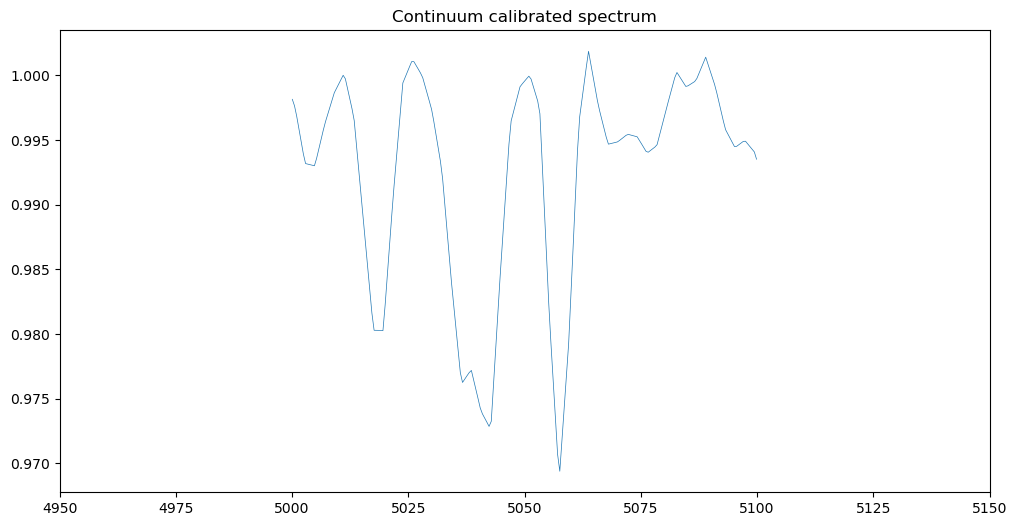

amp = -0.029698075050770878 
mu = 5057.528966685216 
sigma = 2.178546353686834 
offset = 1.0 
chi2 =  1.480550826773452e-05


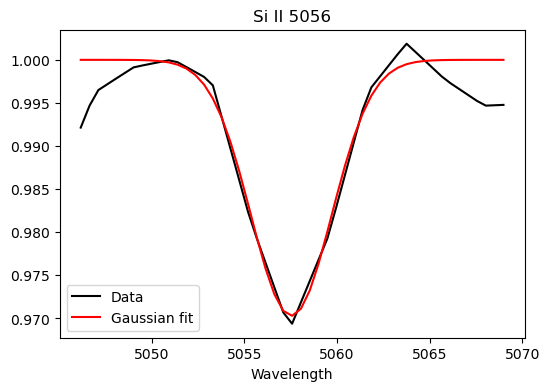

Lambda =  5057.528966685216 Eq Width = 0.16217542309196287 FWHM =  5.130476662932494 Intensity =  -0.029698075050770878


#### Si II 5056 optimization

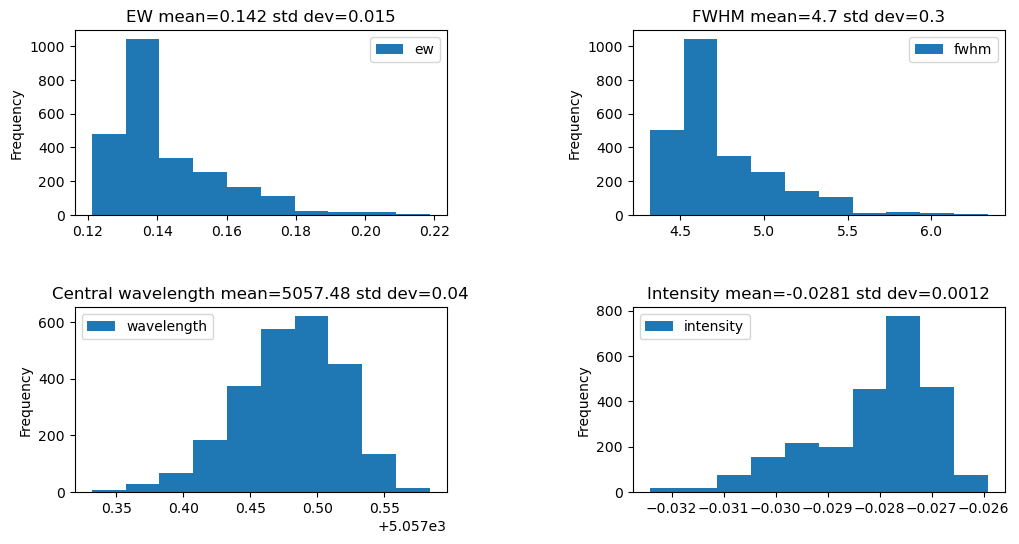

#### Si II 5056 re-fit with best parameters

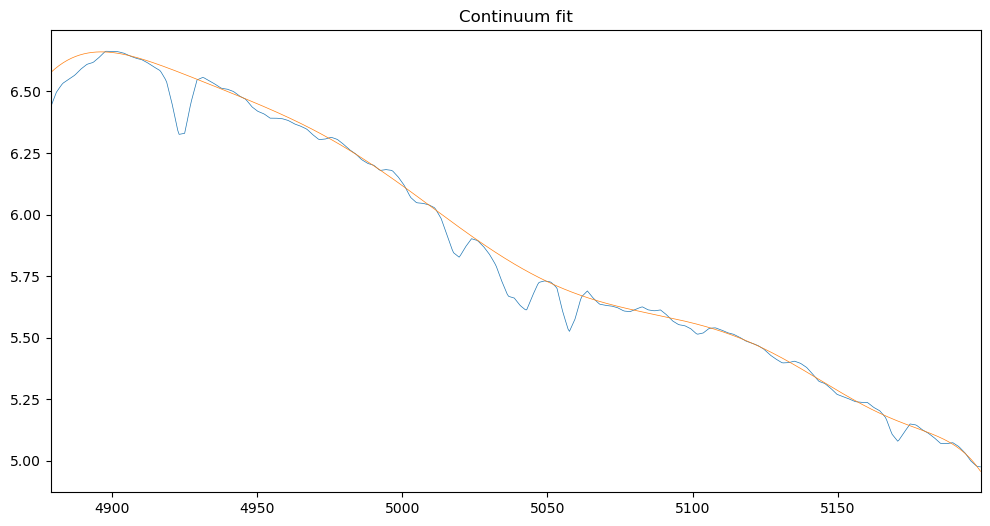

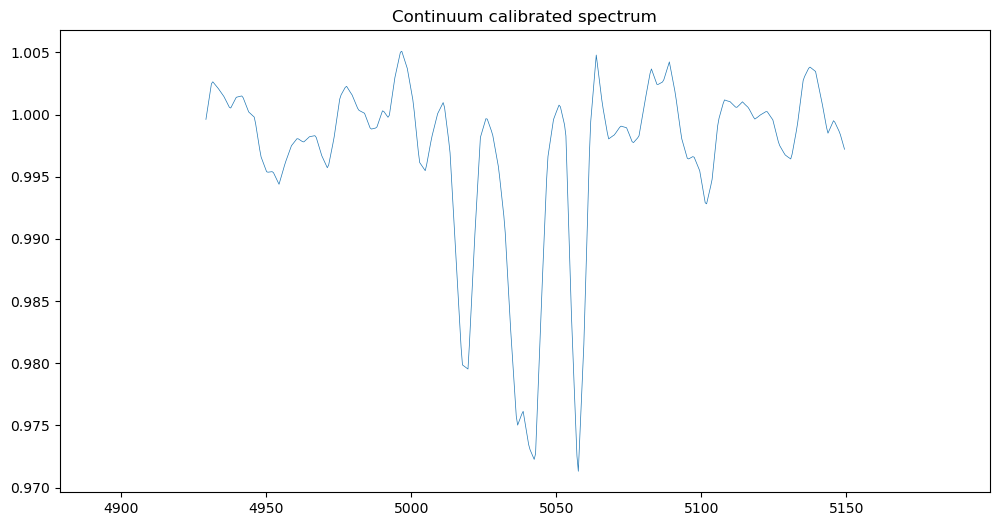

amp = -0.028143155947850575 
mu = 5057.463918735129 
sigma = 2.0097618573630682 
offset = 1.0 
chi2 =  2.495423732229334e-05


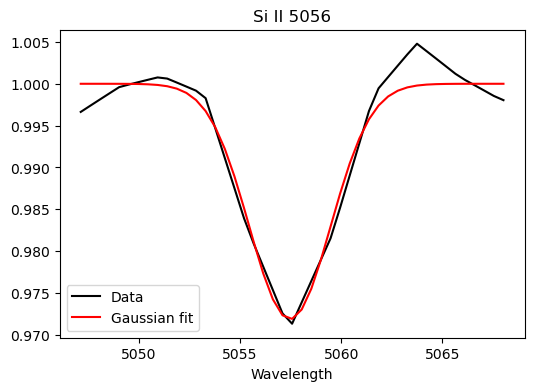

Lambda =  5057.463918735129 Eq Width = 0.1417775055401411 FWHM =  4.732989174090026 Intensity =  -0.028143155947850575


### Measuring Si II 6347

#### Si II 6347 preliminary fit

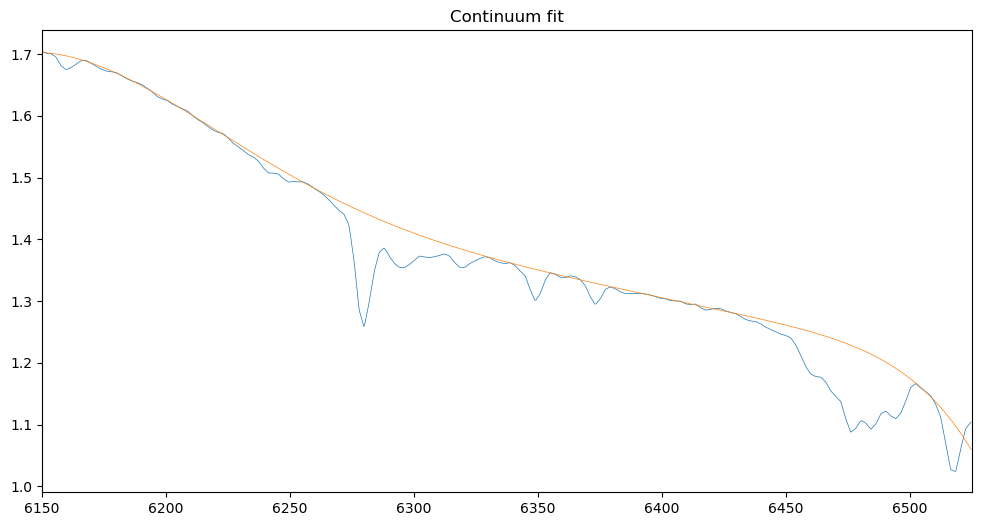

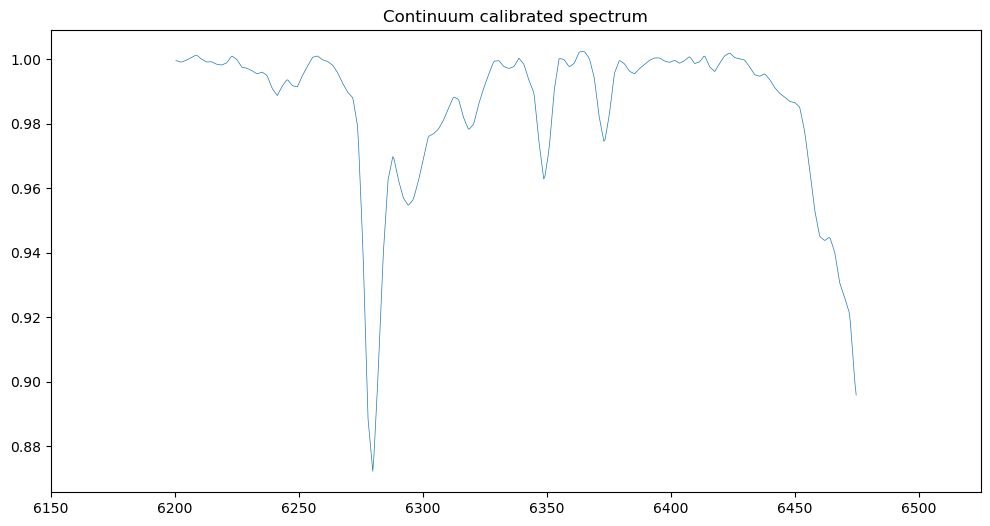

amp = -0.035372059911361095 
mu = 6348.890754980512 
sigma = 2.701390893950423 
offset = 1.0 
chi2 =  7.286204190157034e-05


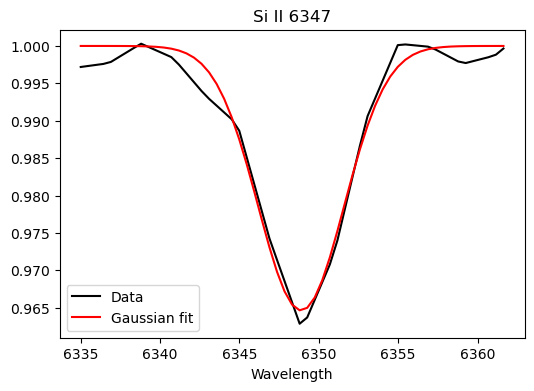

Lambda =  6348.890754980512 Eq Width = 0.23951775792896507 FWHM =  6.361775555253246 Intensity =  -0.035372059911361095


#### Si II 6347 optimization

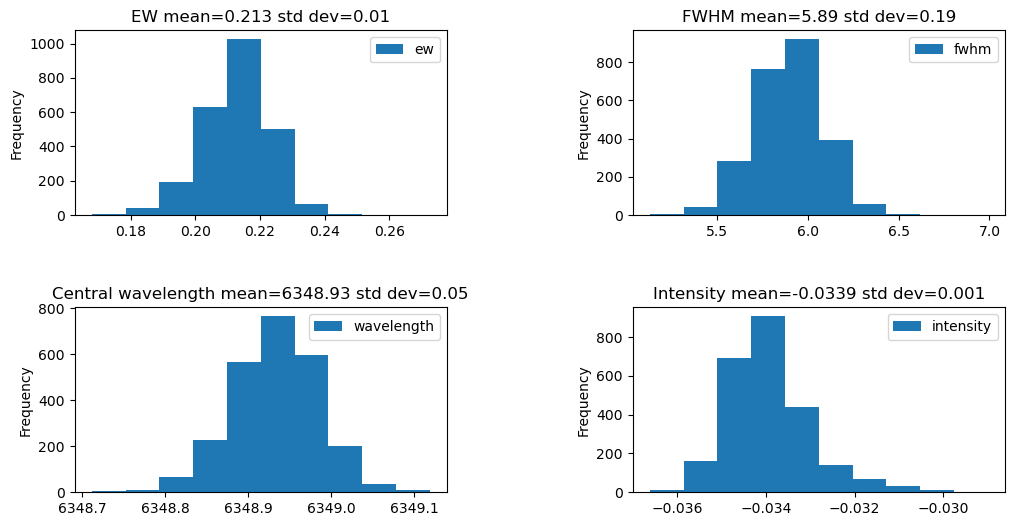

#### Si II 6347 re-fit with best parameters

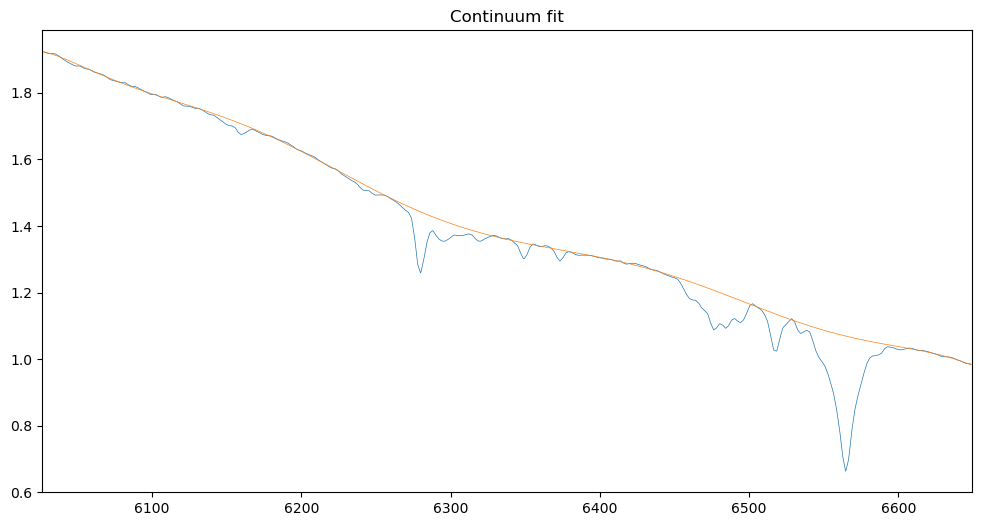

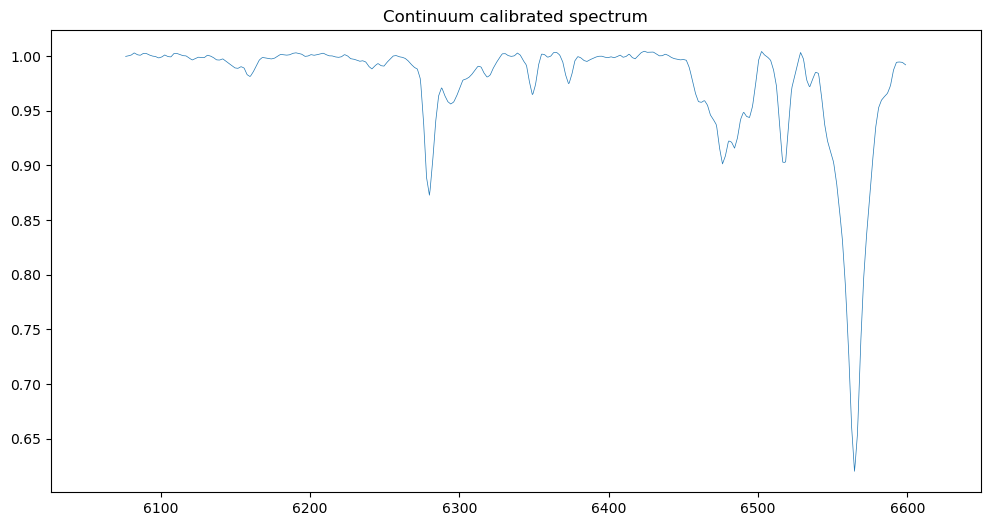

amp = -0.0341545384144307 
mu = 6348.9476718598535 
sigma = 2.492111338582139 
offset = 1.0 
chi2 =  3.597091480811394e-05


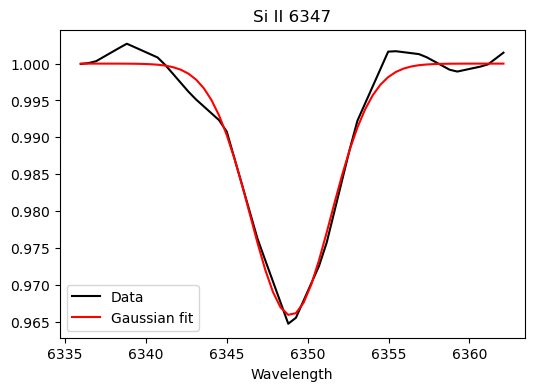

Lambda =  6348.9476718598535 Eq Width = 0.21335645938804412 FWHM =  5.868922202360937 Intensity =  -0.0341545384144307


### Measuring Si II 6371

#### Si II 6371 preliminary fit

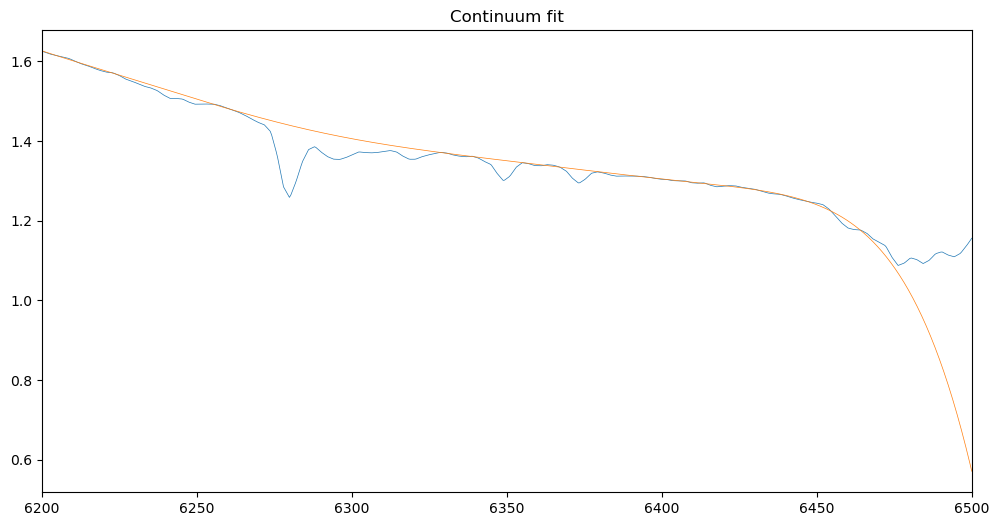

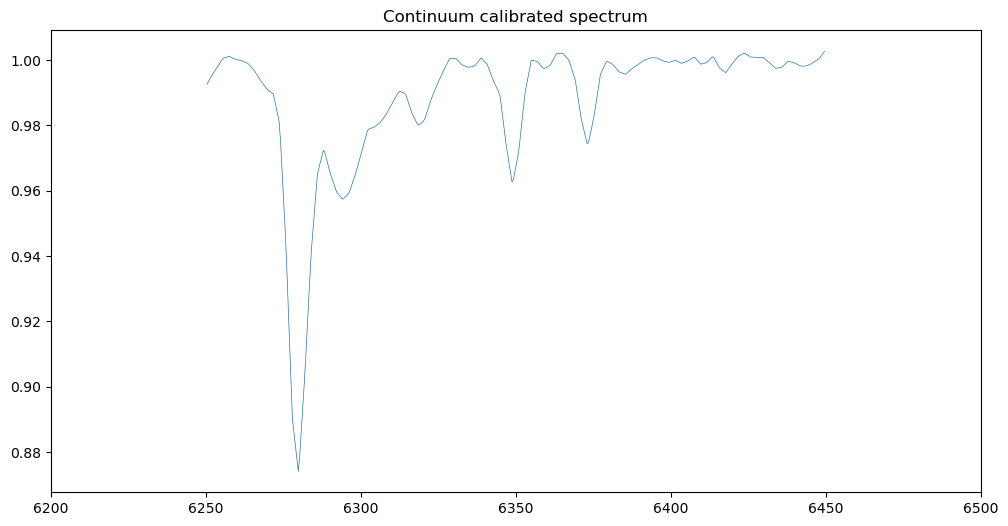

amp = -0.024961830622208046 
mu = 6373.13154015442 
sigma = 2.380730826708444 
offset = 1.0 
chi2 =  4.711815121000595e-06


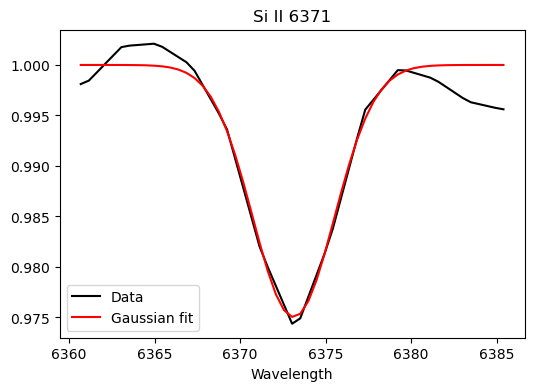

Lambda =  6373.13154015442 Eq Width = 0.14896240025892252 FWHM =  5.606621096898386 Intensity =  -0.024961830622208046


#### Si II 6371 optimization

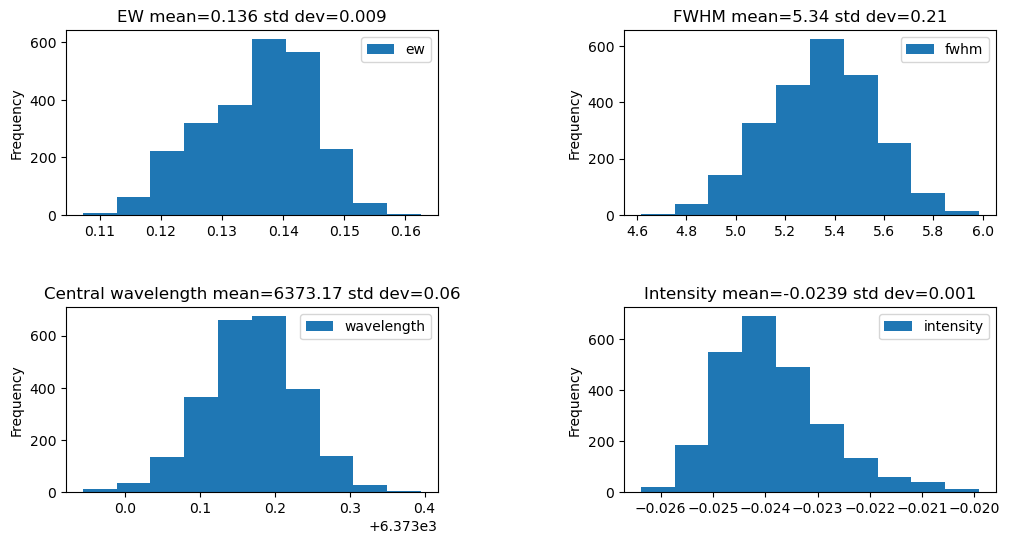

#### Si II 6371 re-fit with best parameters

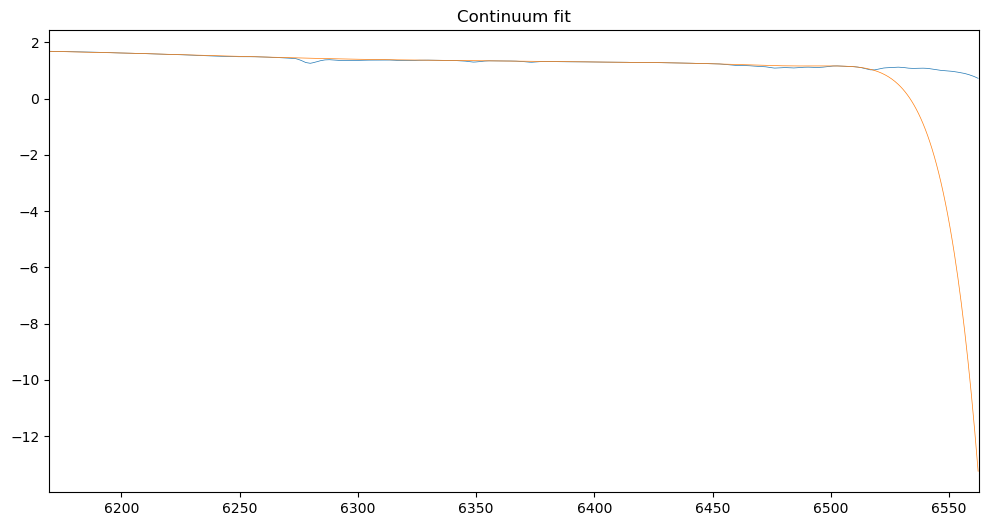

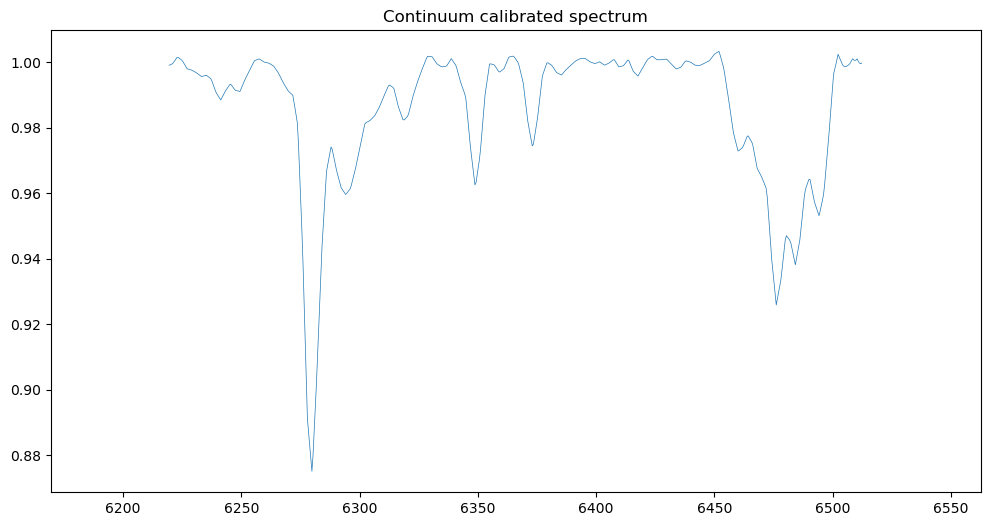

amp = -0.024934674222000897 
mu = 6373.10533910124 
sigma = 2.37538292019244 
offset = 1.0 
chi2 =  5.205274178990518e-06


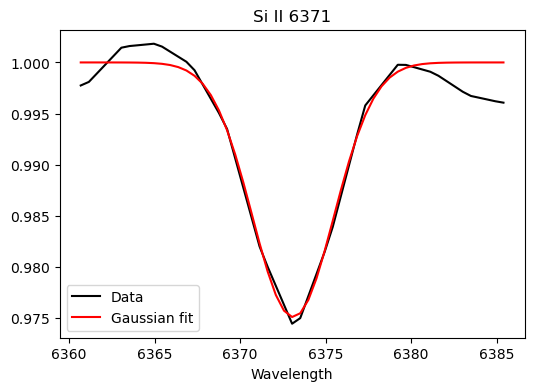

Lambda =  6373.10533910124 Eq Width = 0.1484660868933333 FWHM =  5.594026777053196 Intensity =  -0.024934674222000897


### Measuring He I 4026

#### He I 4026 preliminary fit

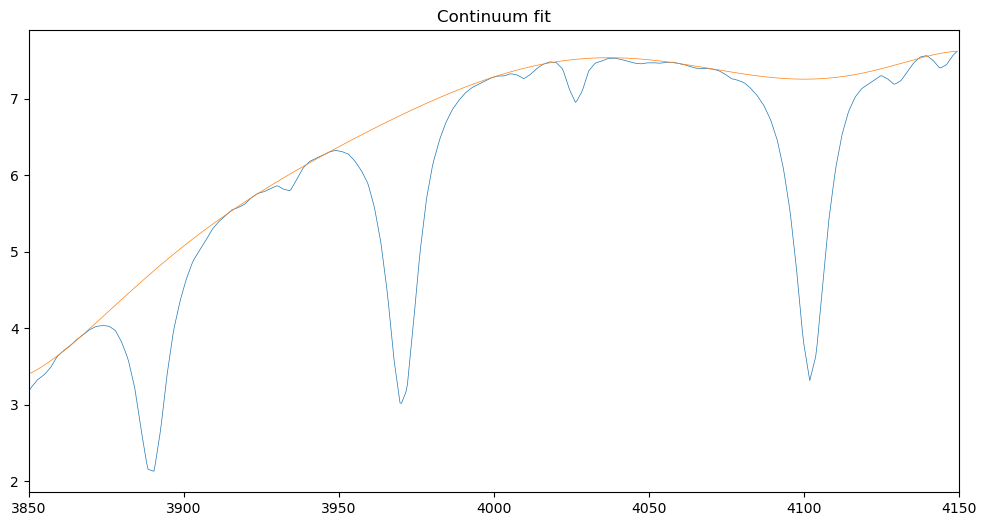

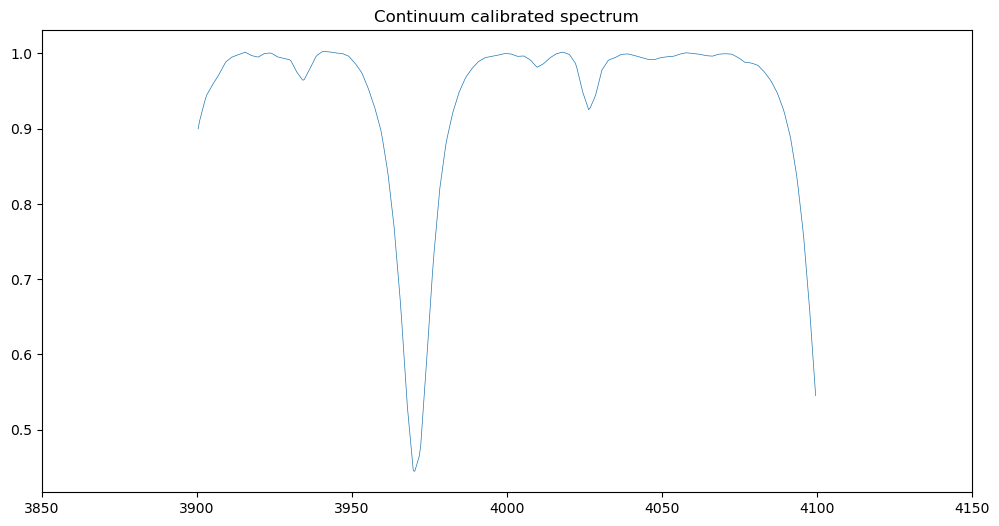

amp = -0.07133643688312868 
mu = 4026.7512974796527 
sigma = 2.6864187448419656 
offset = 1.0 
chi2 =  0.00010822925292380467


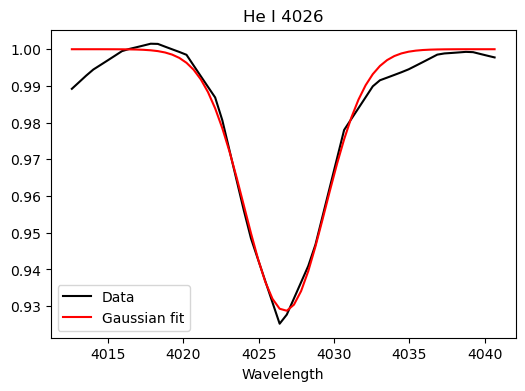

Lambda =  4026.7512974796527 Eq Width = 0.48036909259213334 FWHM =  6.326516144102829 Intensity =  -0.07133643688312868


#### He I 4026 optimization

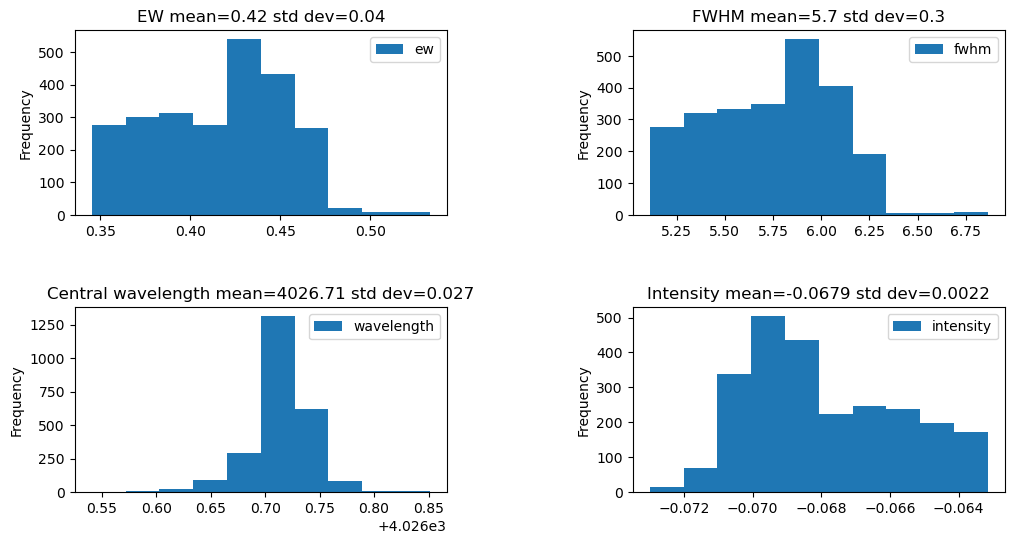

#### He I 4026 re-fit with best parameters

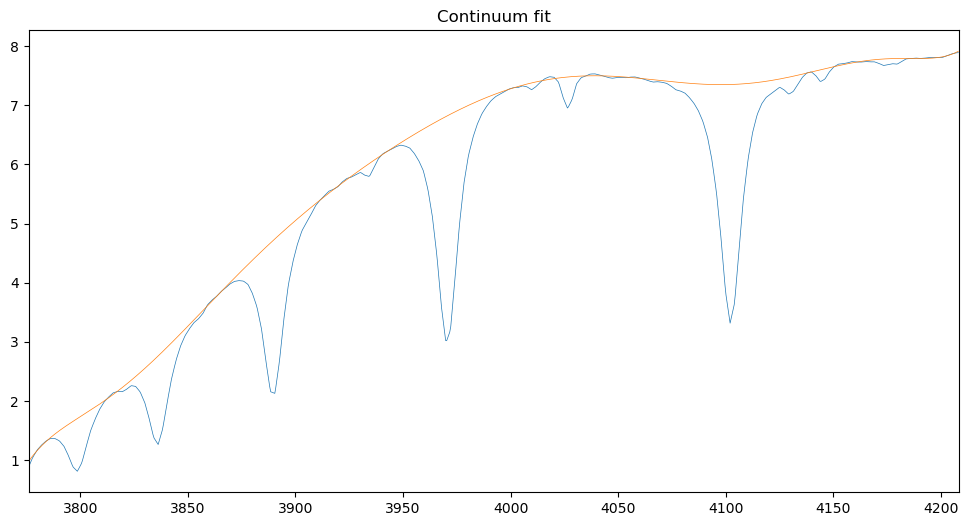

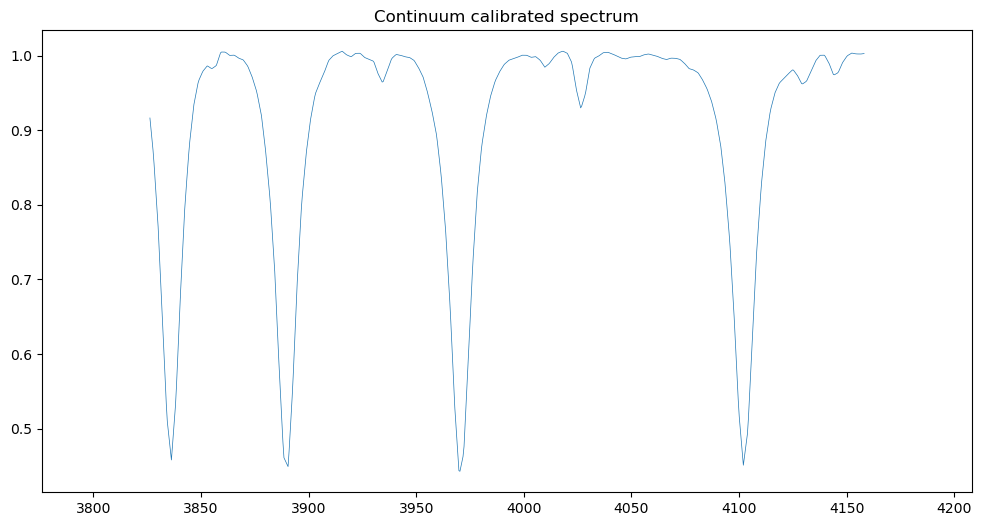

amp = -0.06802860041141787 
mu = 4026.7156037534364 
sigma = 2.430786904832204 
offset = 1.0 
chi2 =  7.311769535465337e-05


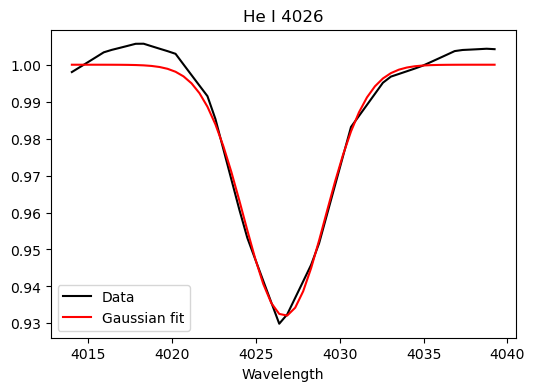

Lambda =  4026.7156037534364 Eq Width = 0.41450364916885196 FWHM =  5.7245031608798405 Intensity =  -0.06802860041141787


### Measuring He I 4922

#### He I 4922 preliminary fit

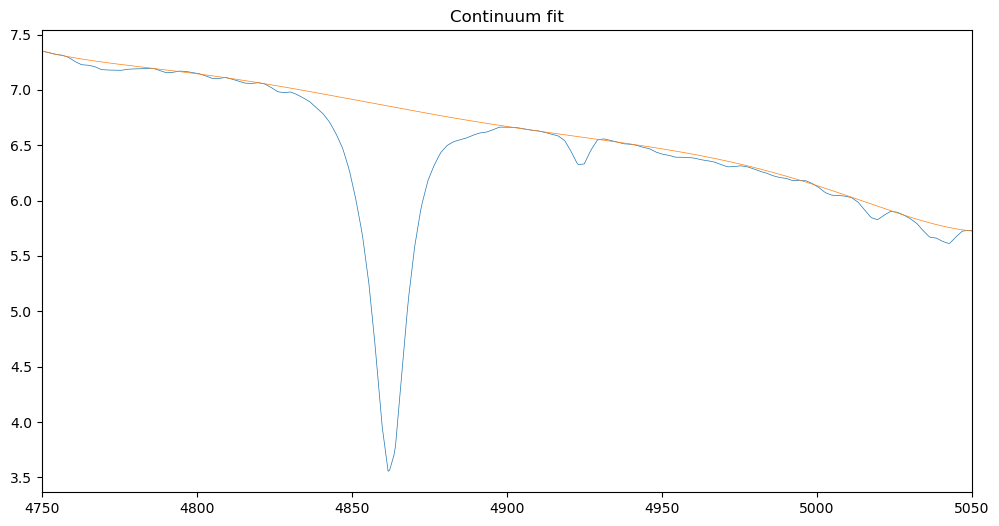

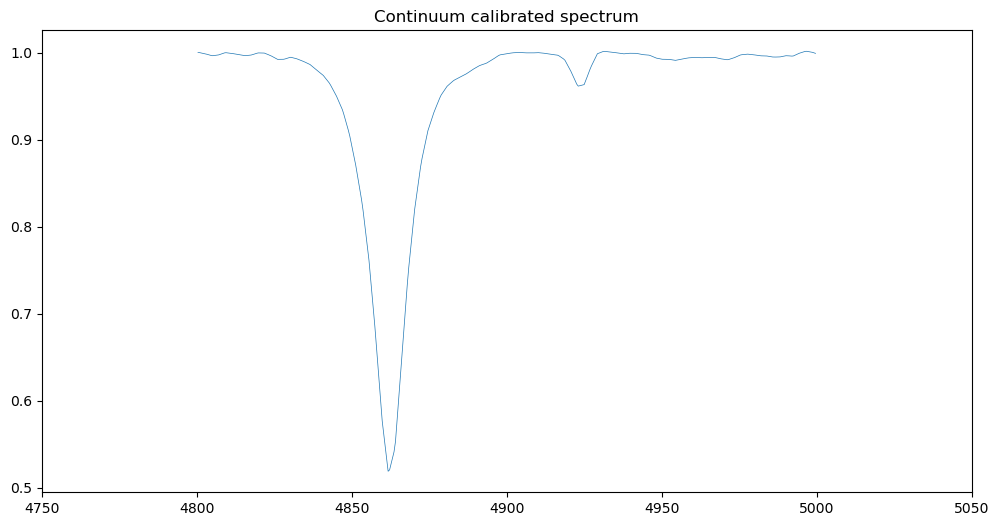

amp = -0.03880259187519549 
mu = 4923.554552424442 
sigma = 2.6936090039995144 
offset = 1.0 
chi2 =  5.0187312164050555e-05


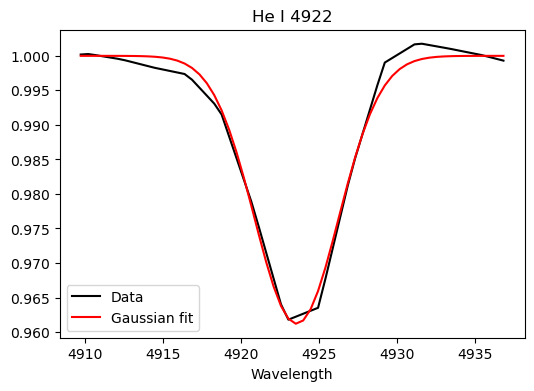

Lambda =  4923.554552424442 Eq Width = 0.26199030784196026 FWHM =  6.343449204418857 Intensity =  -0.03880259187519549


#### He I 4922 optimization

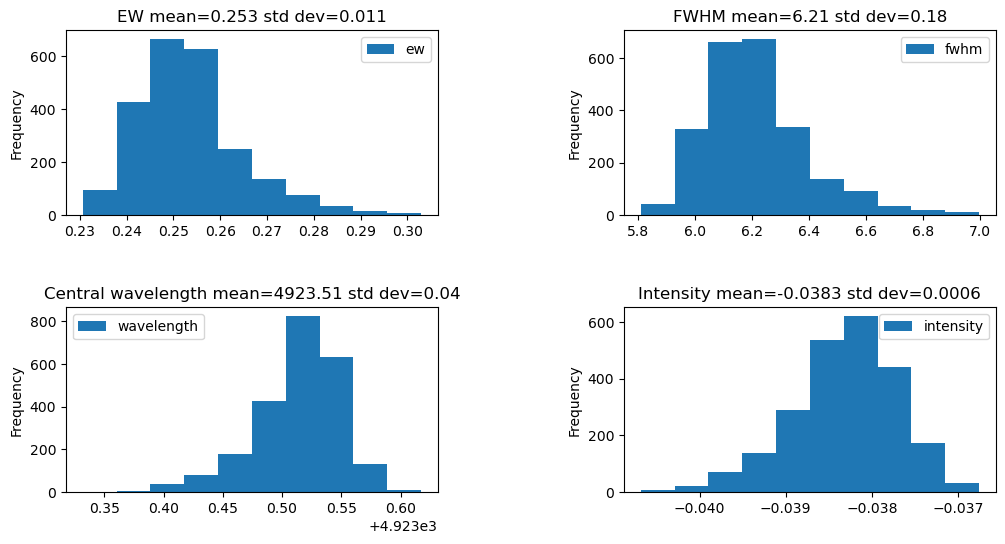

#### He I 4922 re-fit with best parameters

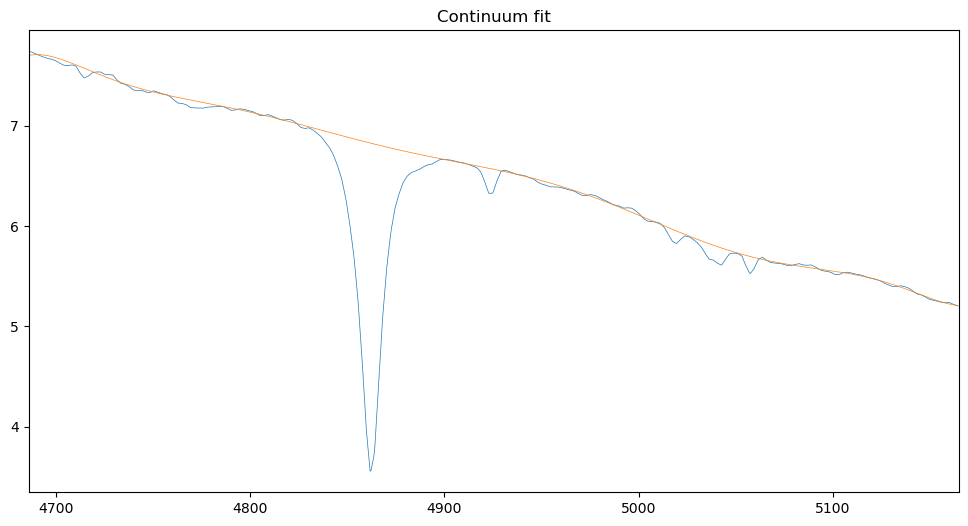

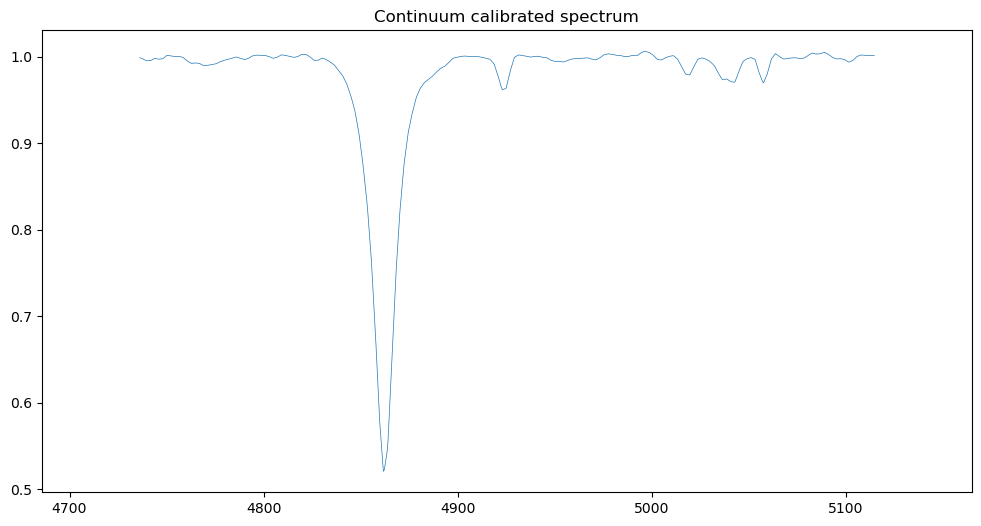

amp = -0.038738625589140936 
mu = 4923.545081653002 
sigma = 2.6756344241232215 
offset = 1.0 
chi2 =  5.442183638254501e-05


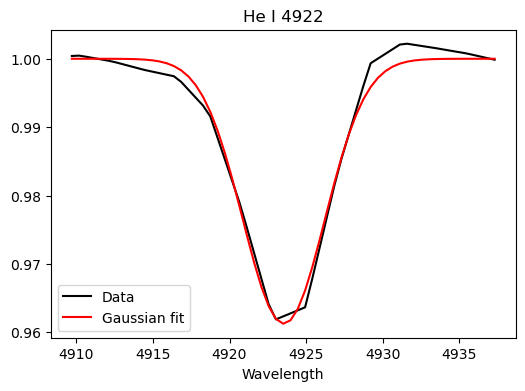

Lambda =  4923.545081653002 Eq Width = 0.2598130237417522 FWHM =  6.301119068810187 Intensity =  -0.038738625589140936


In [31]:
summary_results = pd.DataFrame(columns=("line_name","wavelength","delta_wavelength","ew","delta_ew","fwhm","delta_fwhm","intensity","delta_intensity"))

i = 0

for measuring_line in measuring_lines:
    results = measure_line(wl, flux, measuring_line, show_param_dependencies=SHOW_PARAM_DEPENDENCIES)
    summary_results.loc[i] = results
    i = i + 1

## Measure All Blends

### Measuring H gamma

Blended lines= [{'name': 'H gamma', 'wavelength': 4341.0, 'model': 'voigt'}, {'name': 'He I 4388', 'wavelength': 4388.0}]


#### H gamma preliminary fit

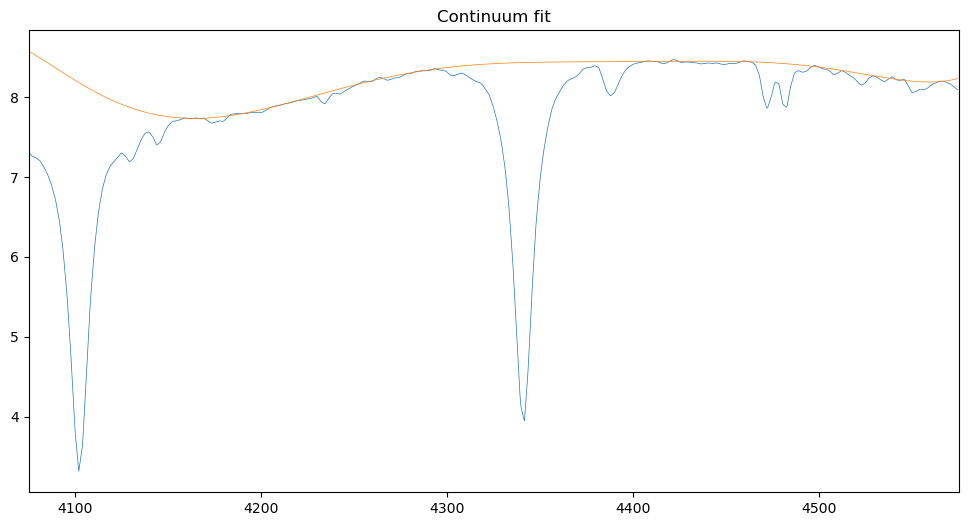

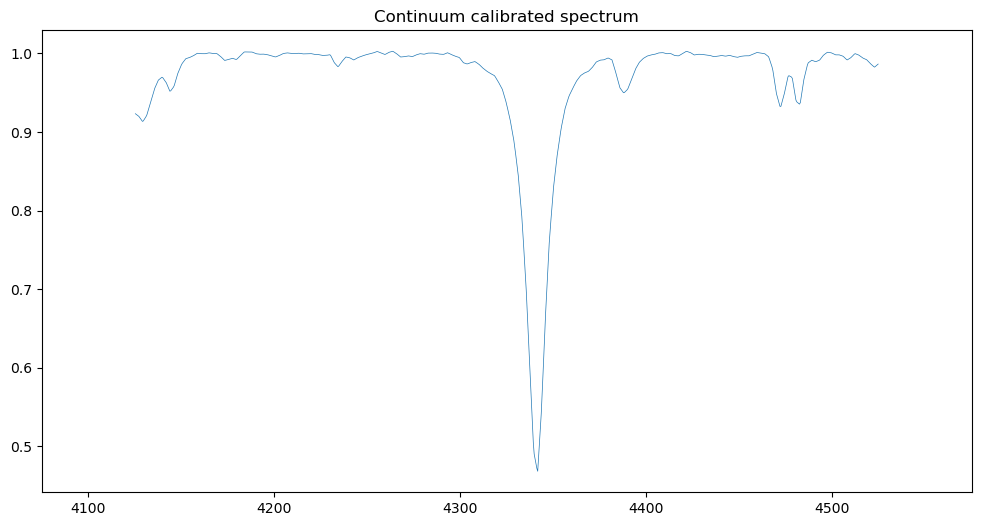

Fit window = (4282.2, 4446.8)
H gamma (voigt)
amp = -10.130747224641793 
mu = 4340.947816776971 
sigma = 1.9318235365794174 
gamma = 5.604280206624584 
offset = 1.0 
chi2 = 0.00614957142526821


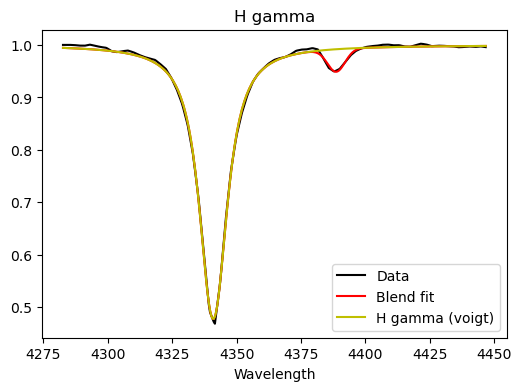

He I 4388 (gauss)
amp = -0.04305906271064715 
mu = 4388.6596943559525 
sigma = 3.4041245798580366 
offset = 1.0 
chi2 = 0.00614957142526821


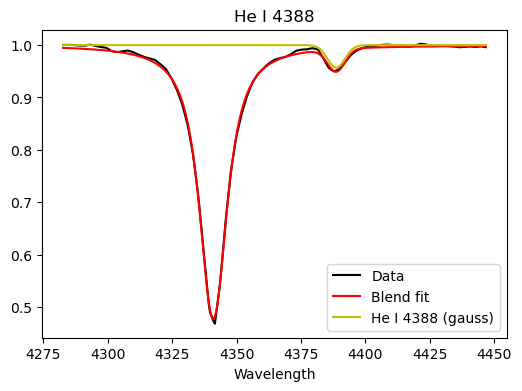

#### H gamma optimization

#### Plotting results for H gamma

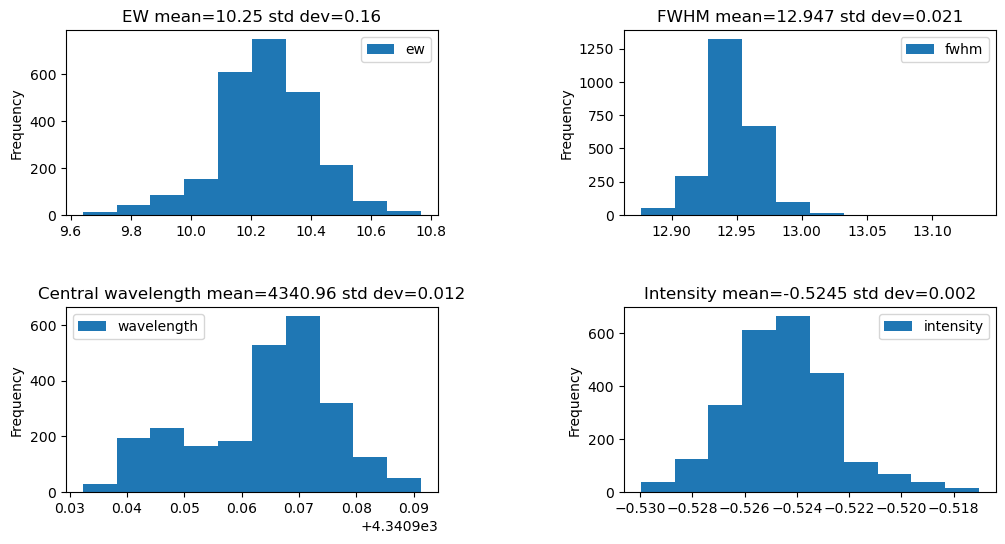

#### Plotting results for He I 4388

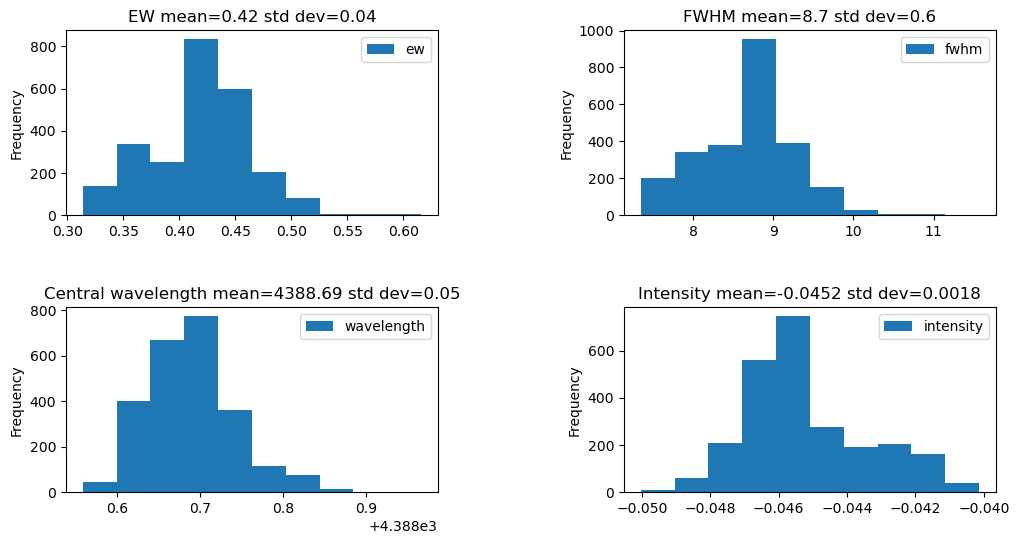

#### H gamma re-fit with best parameters

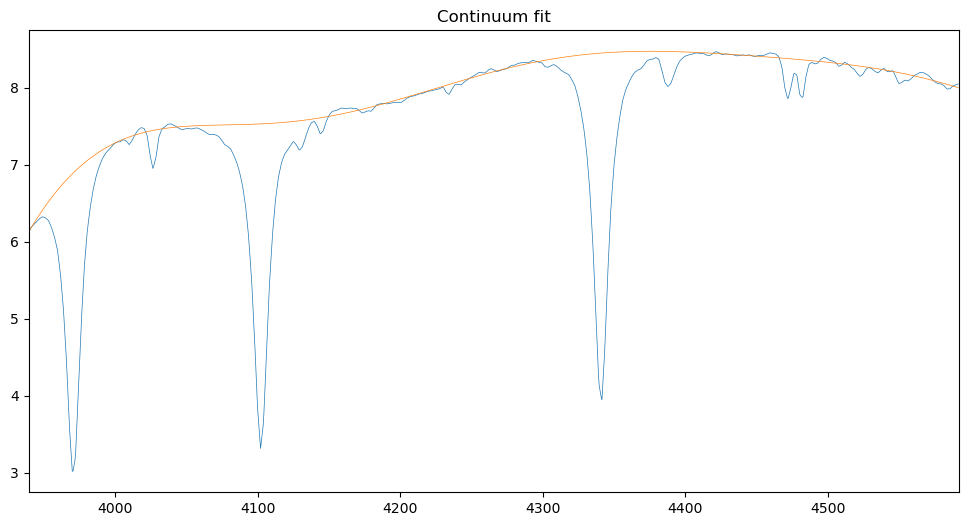

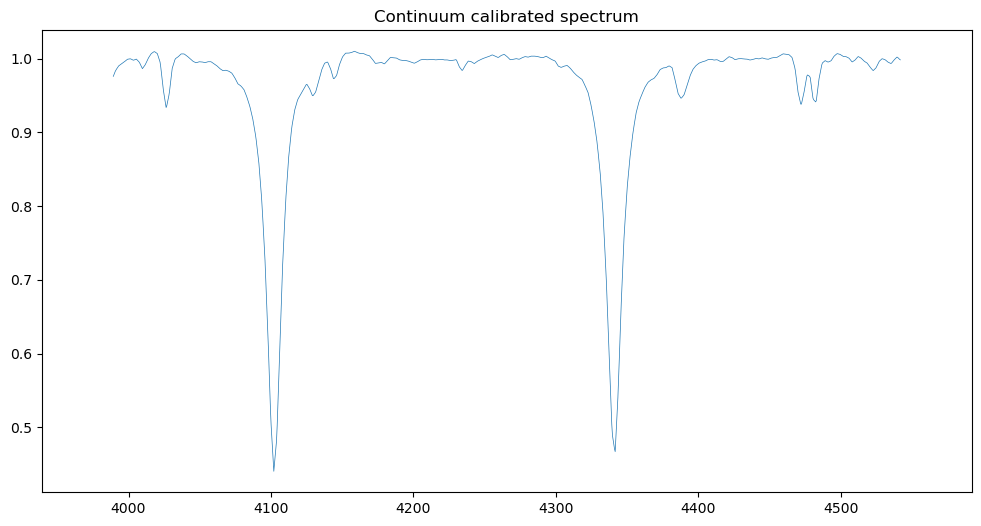

H gamma (voigt)
amp = -10.258564699662093 
mu = 4340.967142269561 
sigma = 1.7935947732753967 
gamma = 5.74117300529772 
offset = 1.0 
chi2 = 0.0075758290886318025


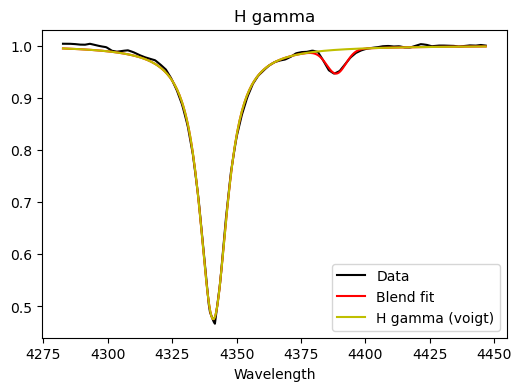

He I 4388 (gauss)
amp = -0.04554320813236557 
mu = 4388.684041525023 
sigma = 3.7034666719209595 
offset = 1.0 
chi2 = 0.0075758290886318025


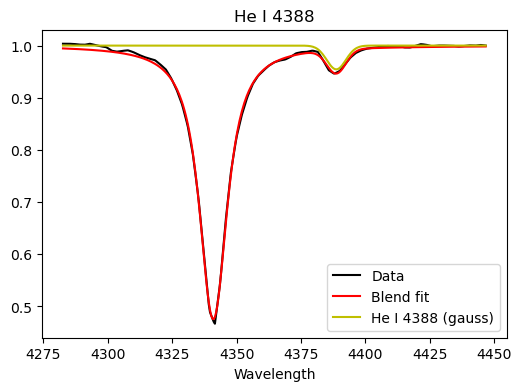

### Measuring H delta

Blended lines= [{'name': 'H delta', 'wavelength': 4101.0, 'model': 'voigt'}, {'name': 'Si II 4128-31', 'wavelength': 4130.0}, {'name': 'He I 4144', 'wavelength': 4144.0}]


#### H delta preliminary fit

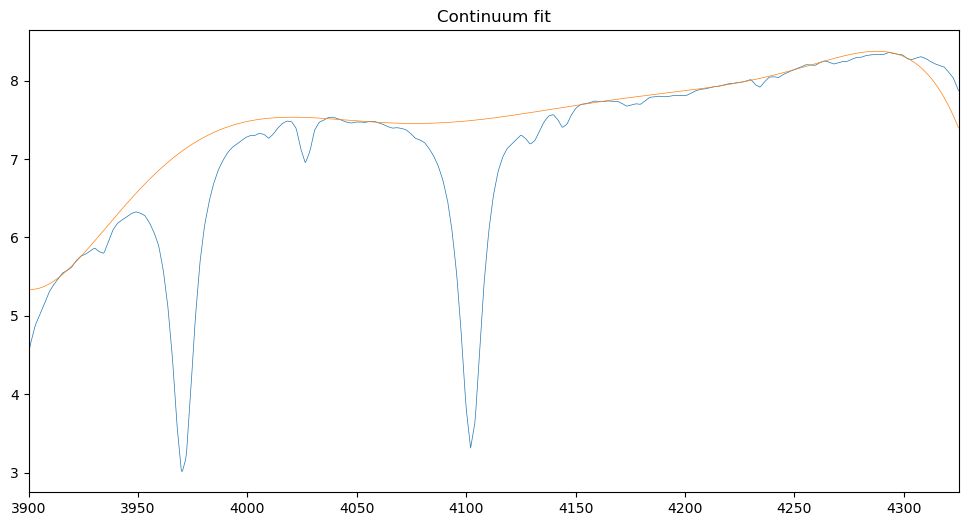

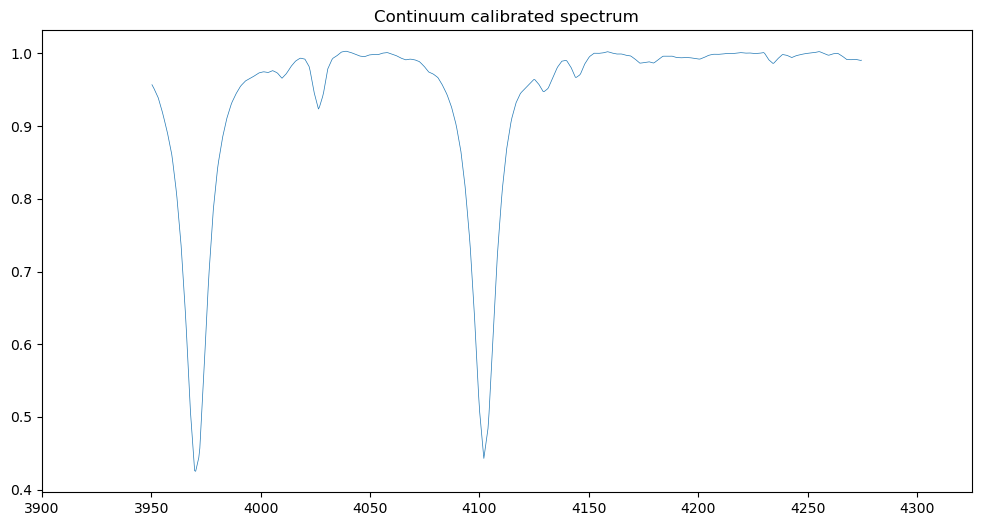

Fit window = (4047.2, 4197.8)
H delta (voigt)
amp = -10.045358686035042 
mu = 4102.1250412039835 
sigma = 2.1114588222975863 
gamma = 5.1877324290039954 
offset = 1.0 
chi2 = 0.008566198195286413


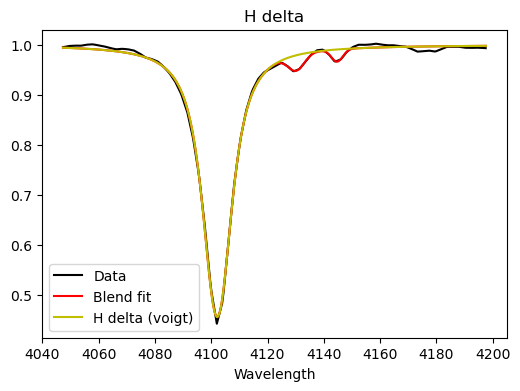

Si II 4128-31 (gauss)
amp = -0.030972601794436845 
mu = 4130.211044304581 
sigma = 2.8576542916056544 
offset = 1.0 
chi2 = 0.008566198195286413


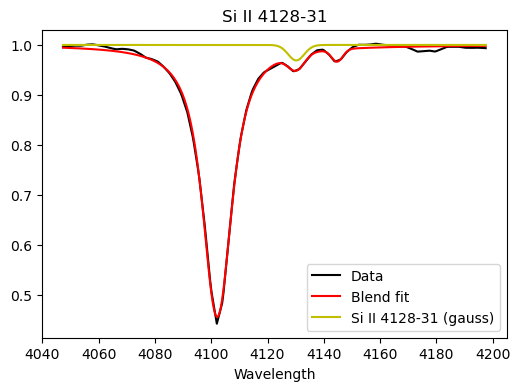

He I 4144 (gauss)
amp = -0.024438188404823886 
mu = 4144.758463469486 
sigma = 1.995450312803736 
offset = 1.0 
chi2 = 0.008566198195286413


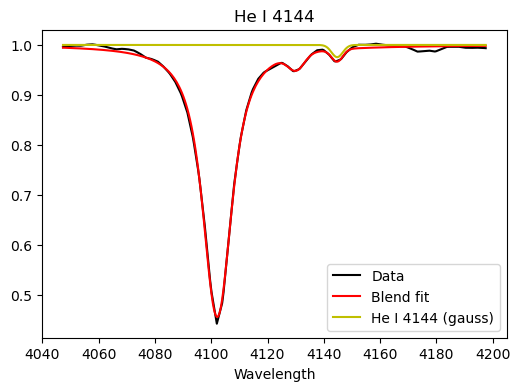

#### H delta optimization

#### Plotting results for H delta

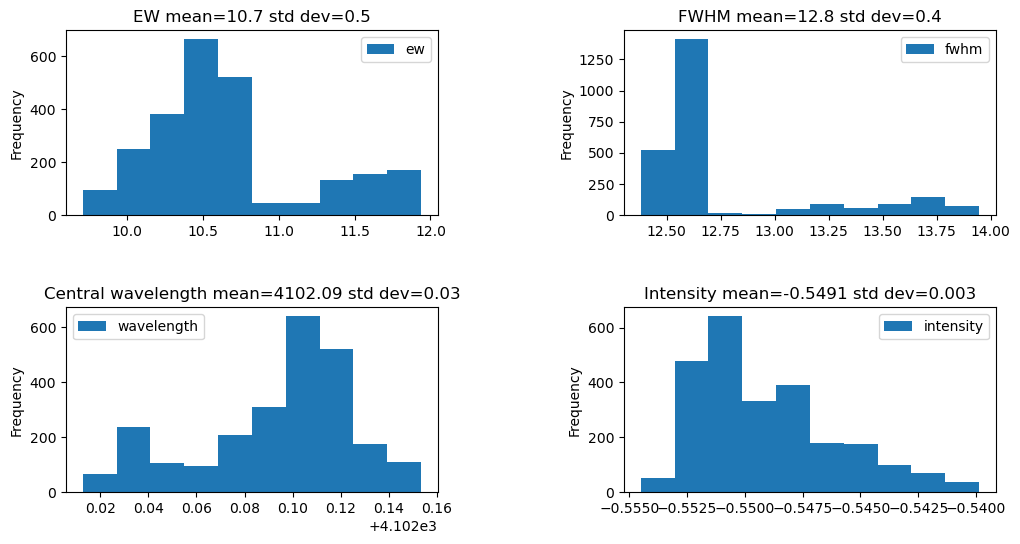

#### Plotting results for Si II 4128-31

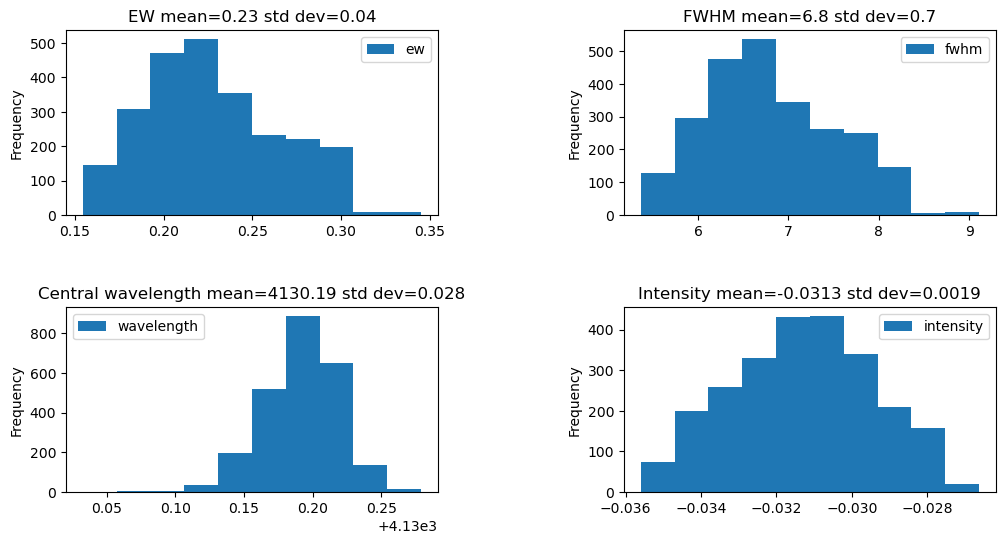

#### Plotting results for He I 4144

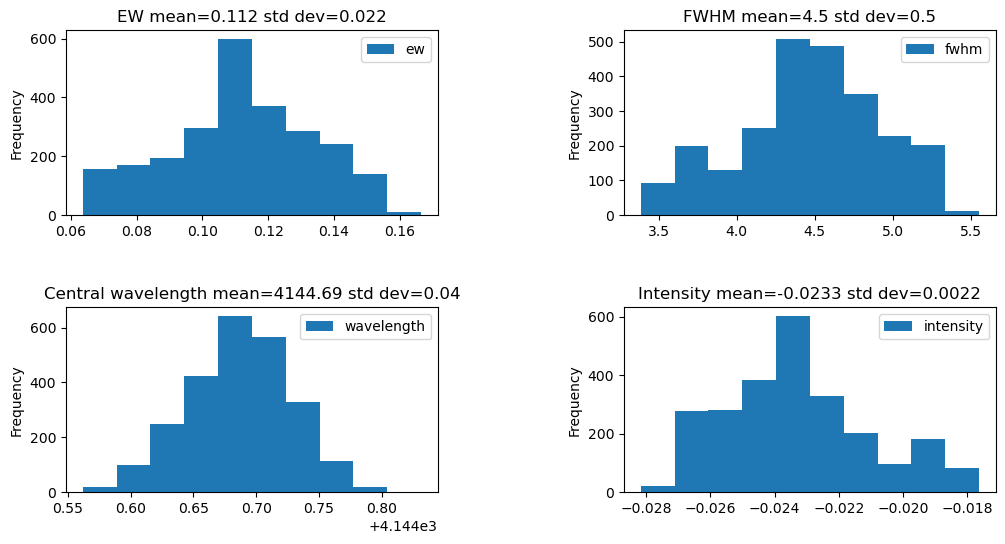

#### H delta re-fit with best parameters

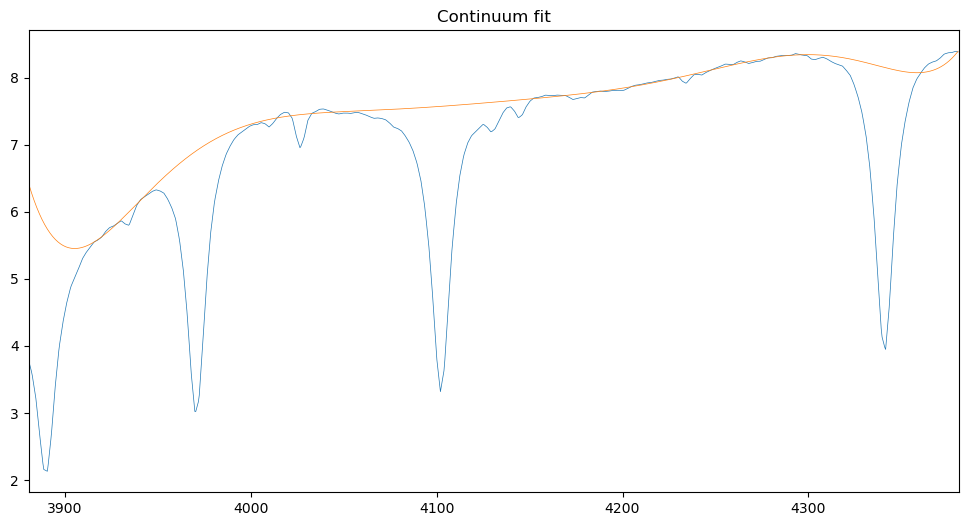

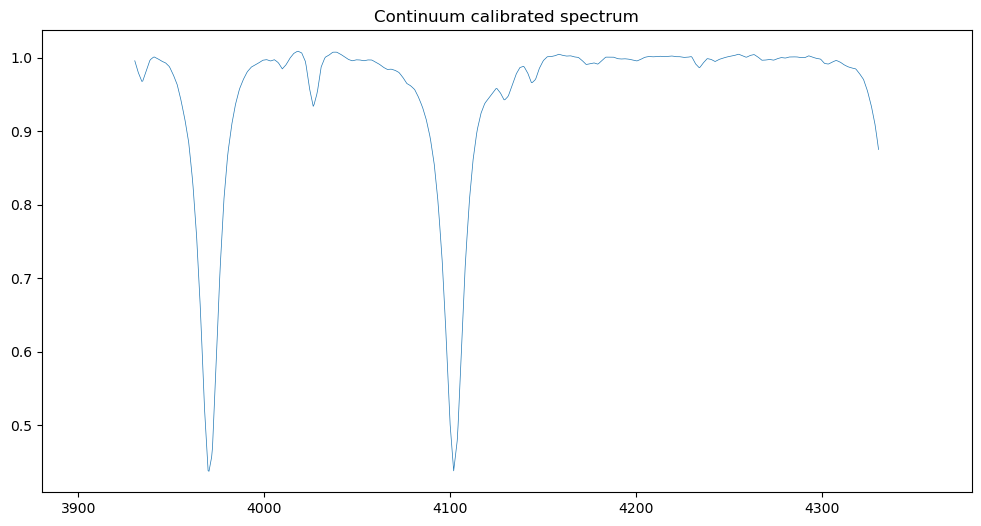

H delta (voigt)
amp = -10.691021220462252 
mu = 4102.106369556942 
sigma = 1.3628591799306147 
gamma = 5.880709079310905 
offset = 1.0 
chi2 = 0.007084355918083639


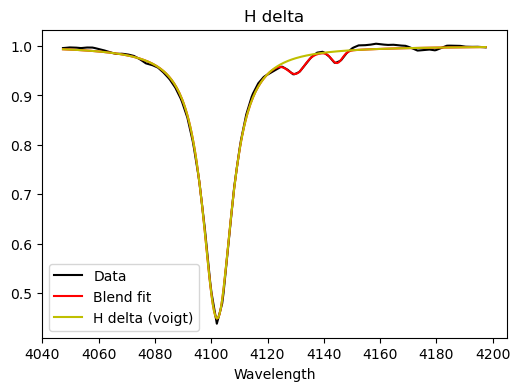

Si II 4128-31 (gauss)
amp = -0.03176449133886191 
mu = 4130.193452095157 
sigma = 2.933536562788737 
offset = 1.0 
chi2 = 0.007084355918083639


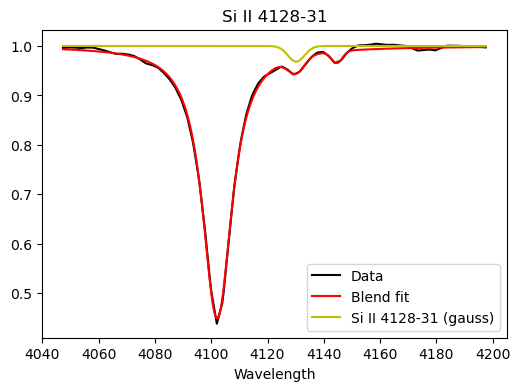

He I 4144 (gauss)
amp = -0.023732766951424098 
mu = 4144.680000436397 
sigma = 1.9251944452246437 
offset = 1.0 
chi2 = 0.007084355918083639


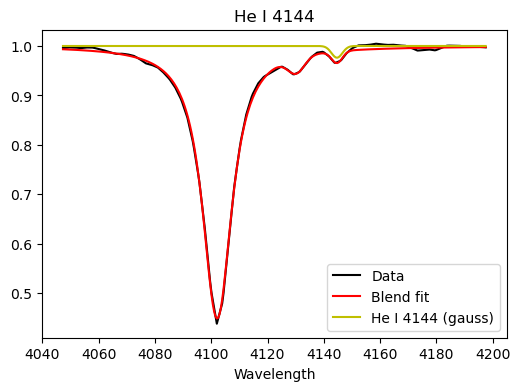

### Measuring Mg II 4481

Blended lines= [{'name': 'Mg II 4481', 'wavelength': 4481.0}, {'name': 'He I 4471', 'wavelength': 4470.0}, {'name': 'Fe II 4489-91', 'wavelength': 4490.0}]


#### Mg II 4481 preliminary fit

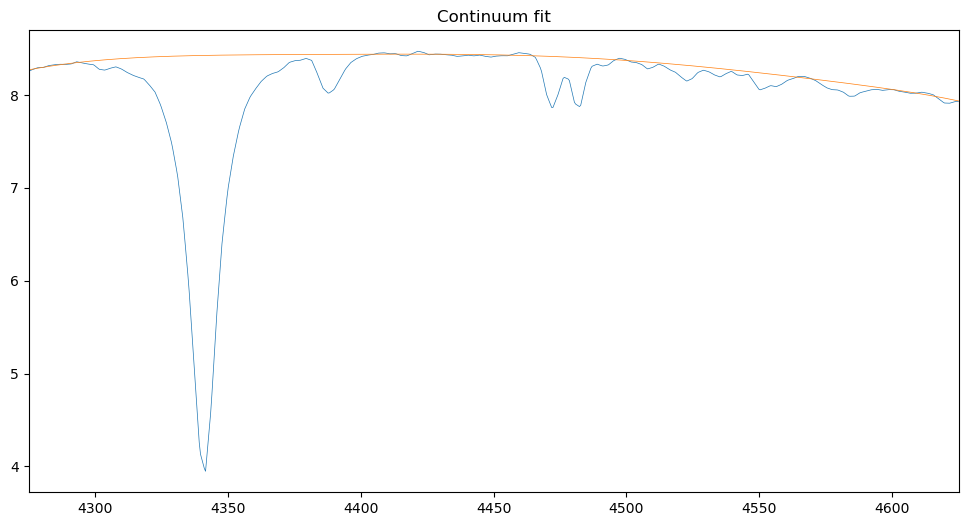

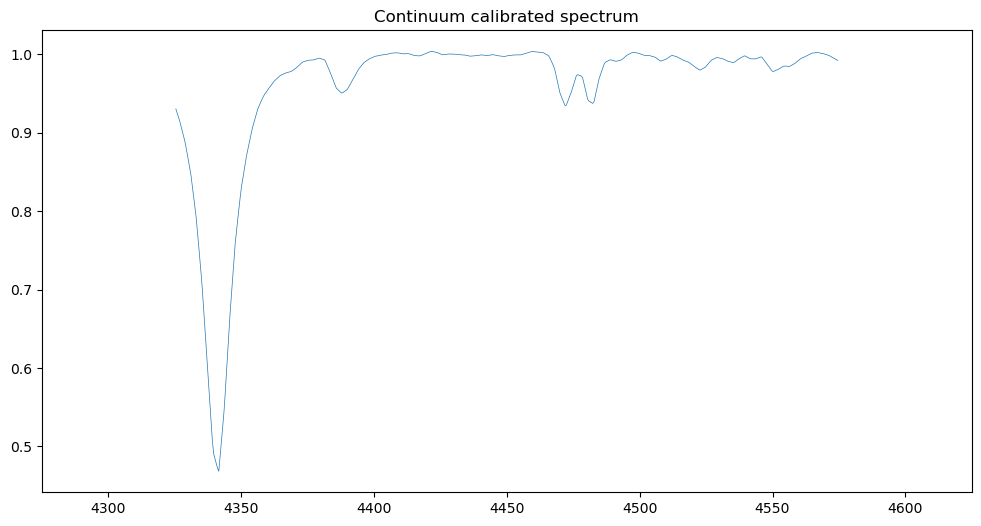

Fit window = (4445.0, 4515.0)
Mg II 4481 (gauss)
amp = -0.06277731367785012 
mu = 4481.76561740174 
sigma = 2.5975588328695487 
offset = 1.0 
chi2 = 0.0009383507217142001


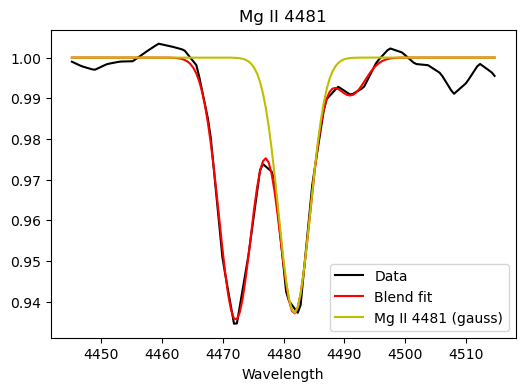

He I 4471 (gauss)
amp = -0.06442026239240899 
mu = 4472.128512568017 
sigma = 2.727895846536585 
offset = 1.0 
chi2 = 0.0009383507217142001


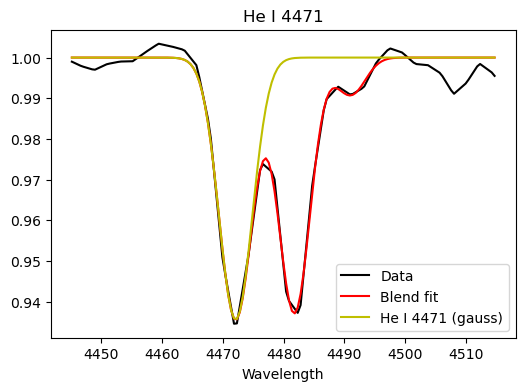

Fe II 4489-91 (gauss)
amp = -0.009198760015784145 
mu = 4491.005923499421 
sigma = 2.3794193802675543 
offset = 1.0 
chi2 = 0.0009383507217142001


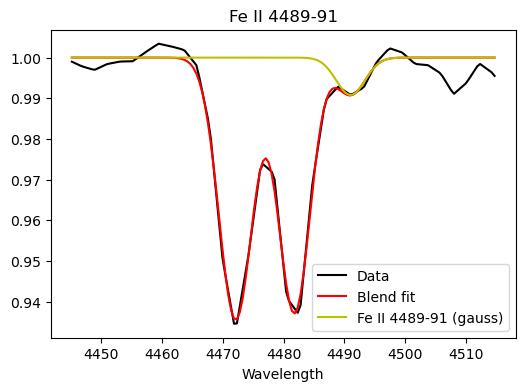

#### Mg II 4481 optimization

#### Plotting results for Mg II 4481

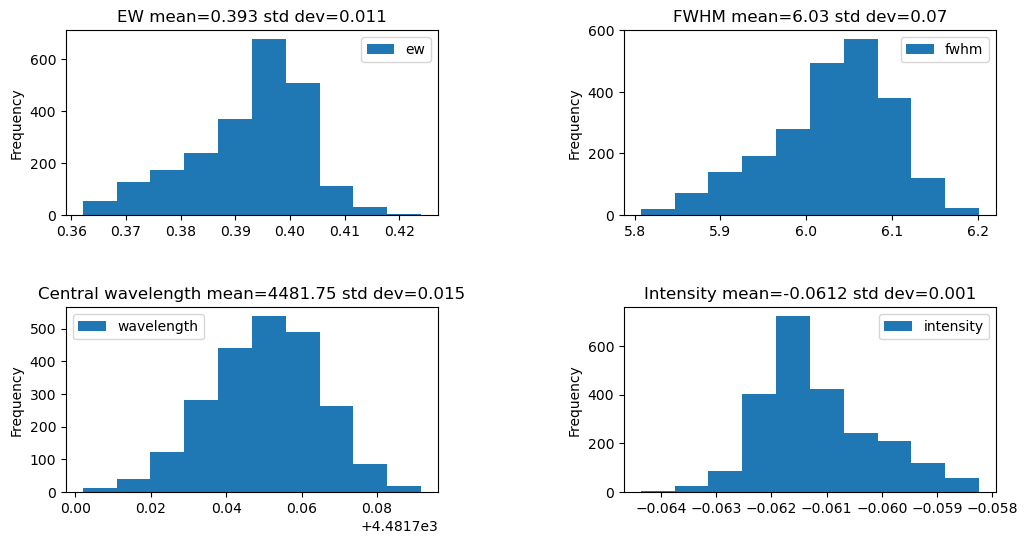

#### Plotting results for He I 4471

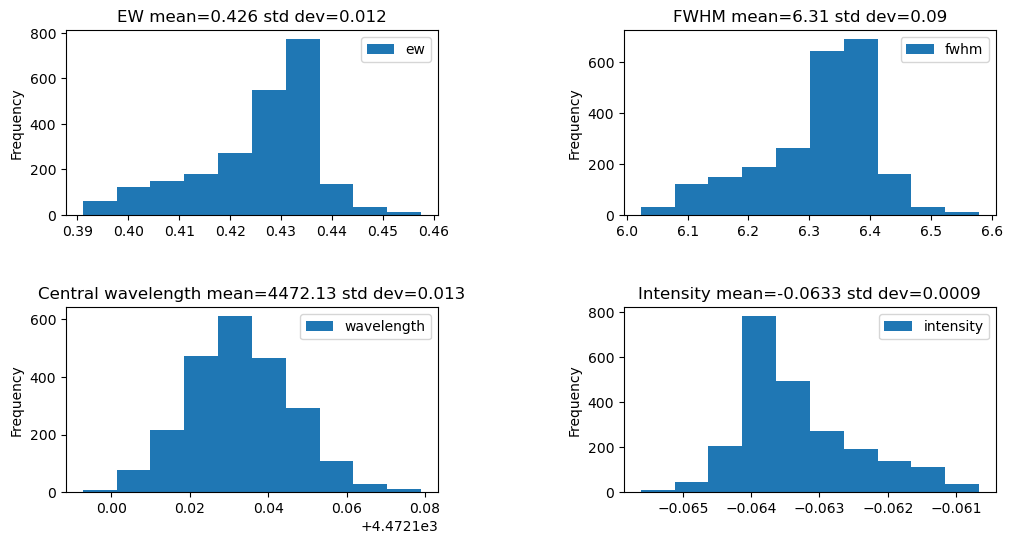

#### Plotting results for Fe II 4489-91

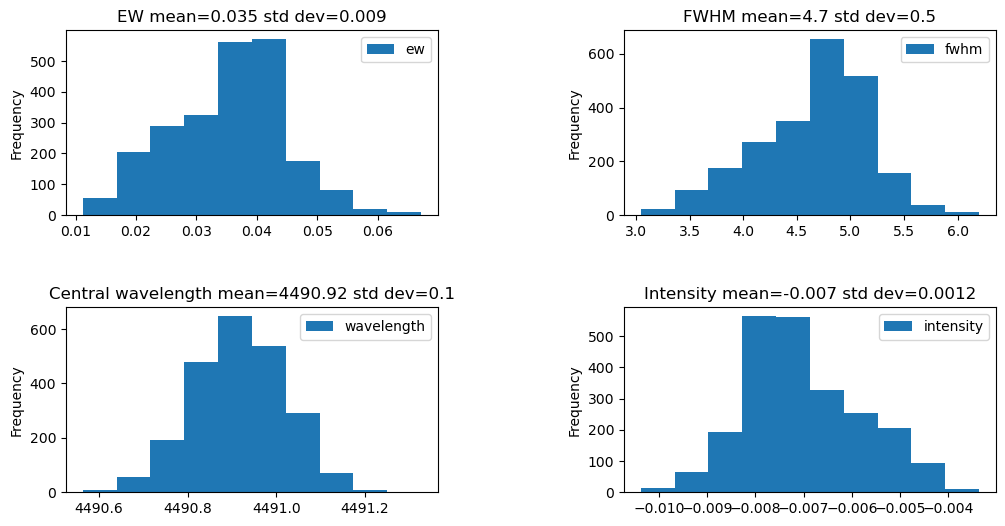

#### Mg II 4481 re-fit with best parameters

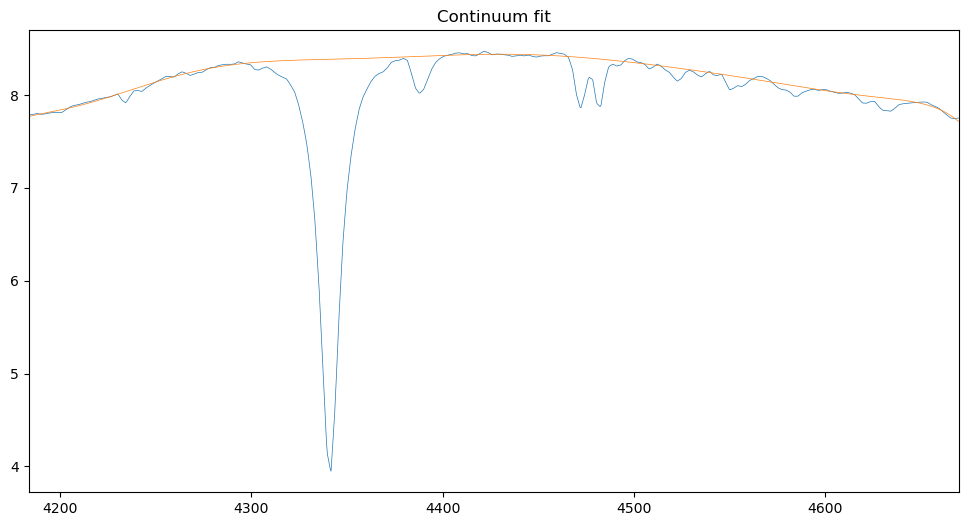

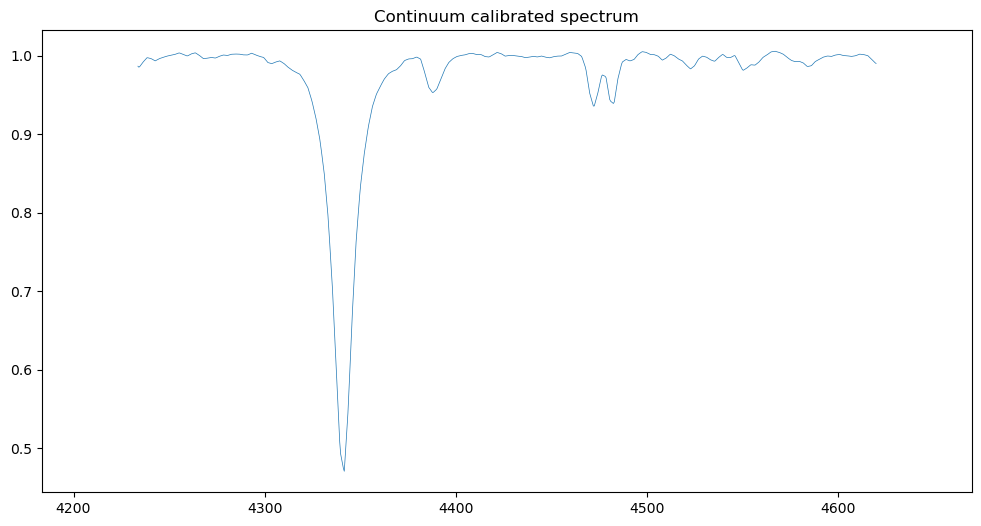

Mg II 4481 (gauss)
amp = -0.06115011730181315 
mu = 4481.750550897341 
sigma = 2.5604509208899158 
offset = 1.0 
chi2 = 0.0006831243997600306


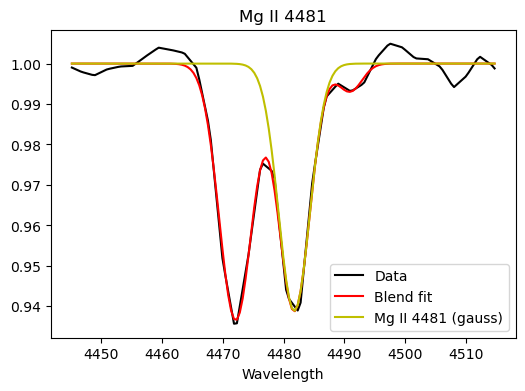

He I 4471 (gauss)
amp = -0.0634096063124835 
mu = 4472.128649694983 
sigma = 2.6884964997180534 
offset = 1.0 
chi2 = 0.0006831243997600306


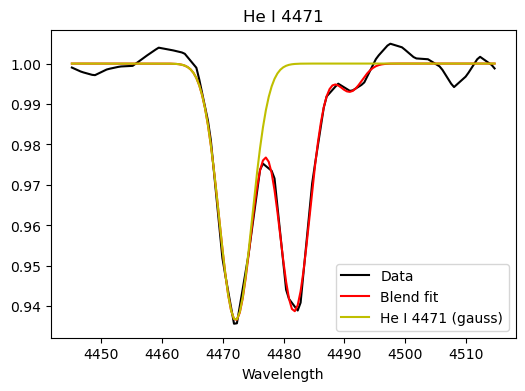

Fe II 4489-91 (gauss)
amp = -0.0068865806995582965 
mu = 4490.896949766738 
sigma = 1.9637840441633687 
offset = 1.0 
chi2 = 0.0006831243997600306


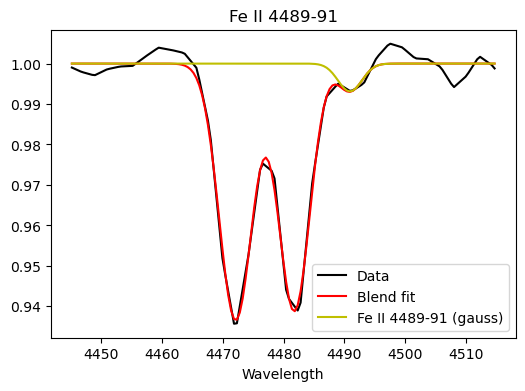

### Measuring Si II 5041

Blended lines= [{'name': 'Unknown 5032', 'wavelength': 5032.0}, {'name': 'Si II 5041', 'wavelength': 5041.0}]


#### Si II 5041 preliminary fit

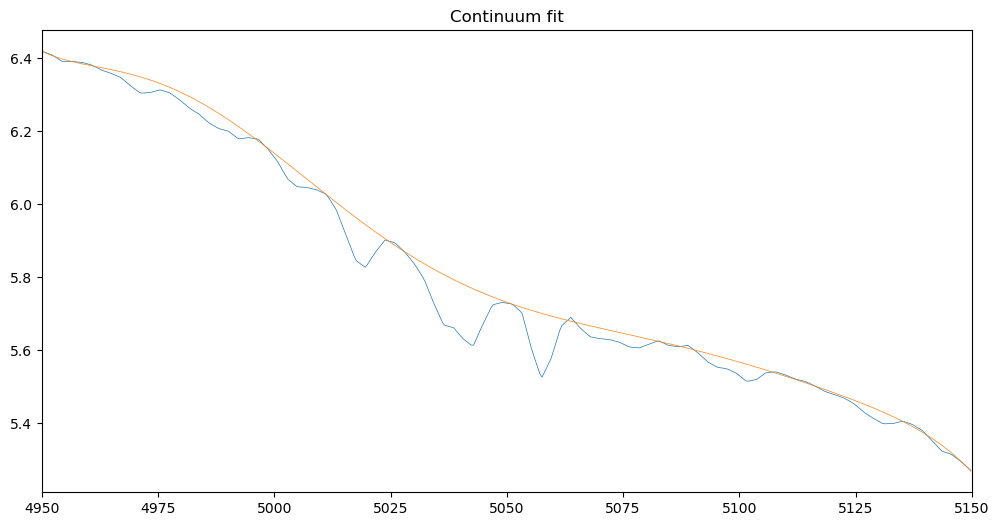

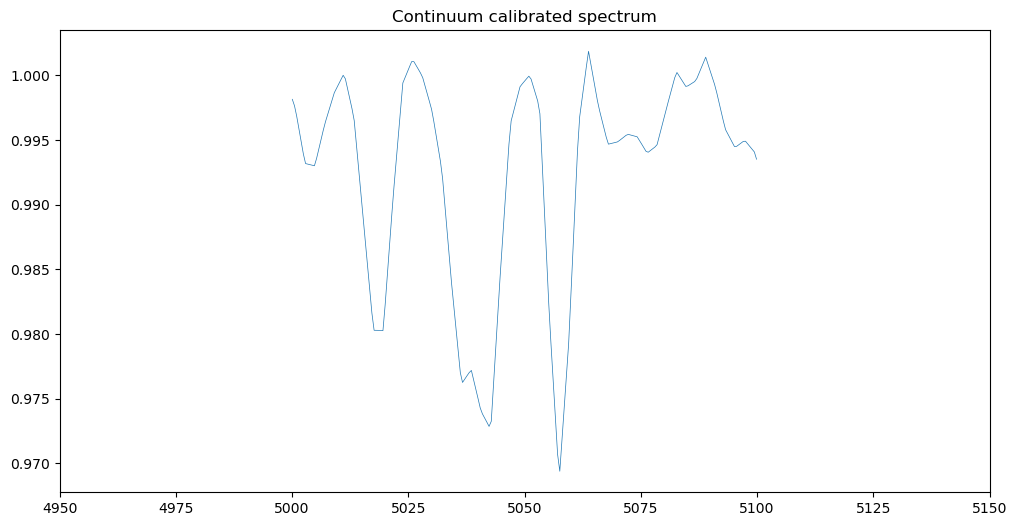

Fit window = (5009.5, 5063.5)
Unknown 5032 (gauss)
amp = -0.015613504456794712 
mu = 5034.999999999999 
sigma = 2.372825526431267 
offset = 1.0 
chi2 = 0.011468532288396123


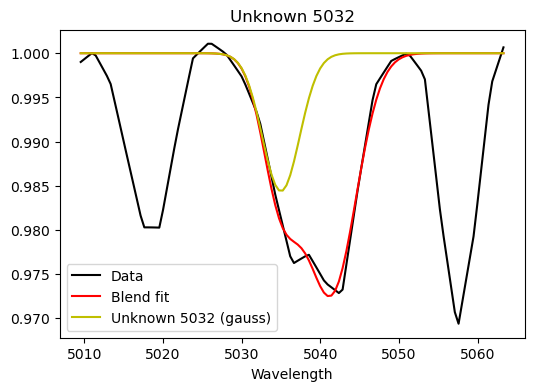

Si II 5041 (gauss)
amp = -0.02702664475543788 
mu = 5041.352165552318 
sigma = 3.183821538740594 
offset = 1.0 
chi2 = 0.011468532288396123


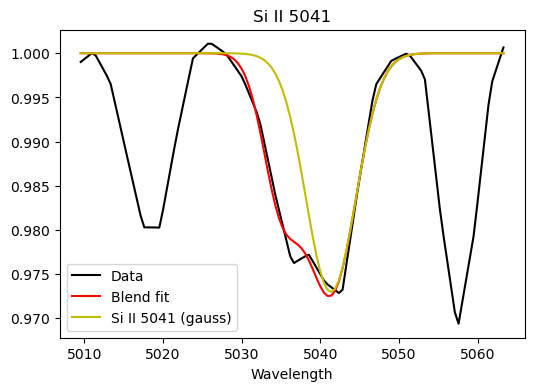

#### Si II 5041 optimization

#### Plotting results for Unknown 5032

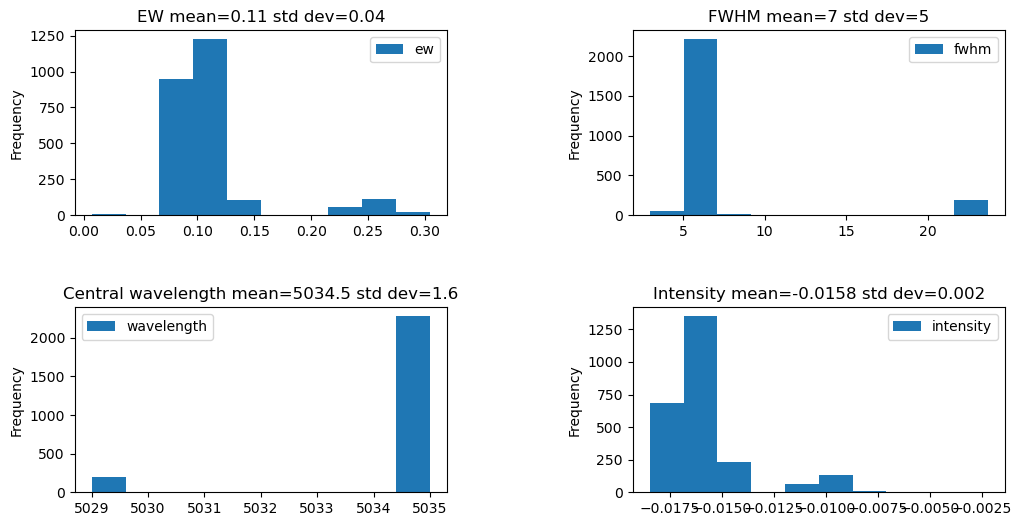

#### Plotting results for Si II 5041

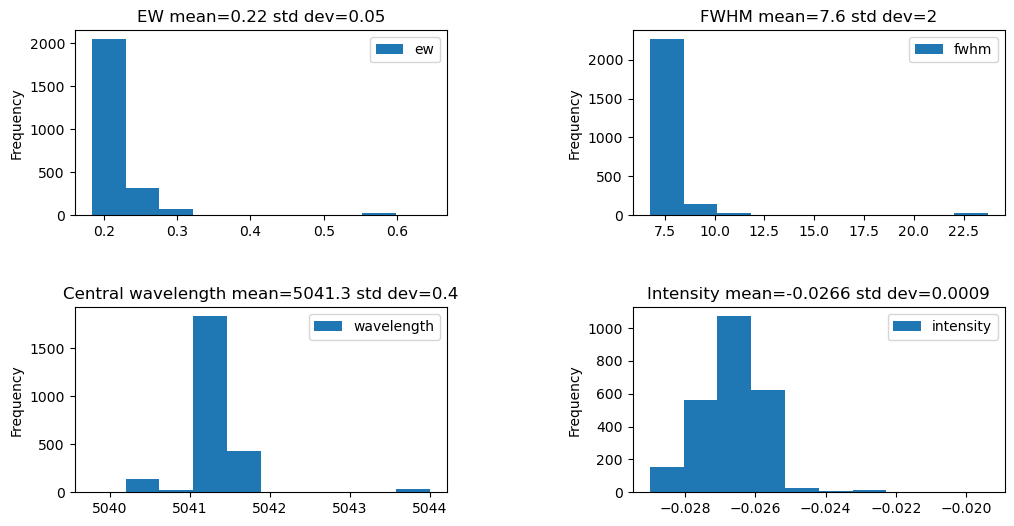

#### Si II 5041 re-fit with best parameters

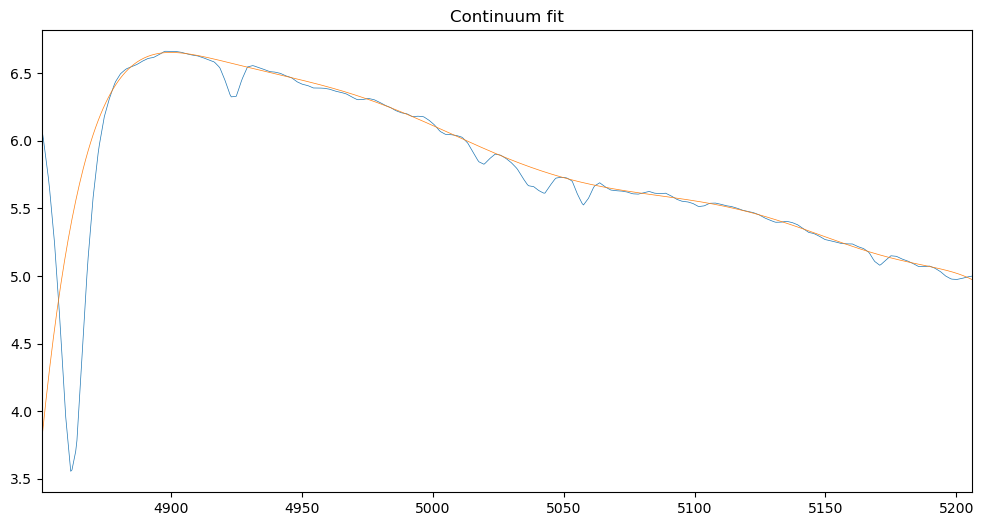

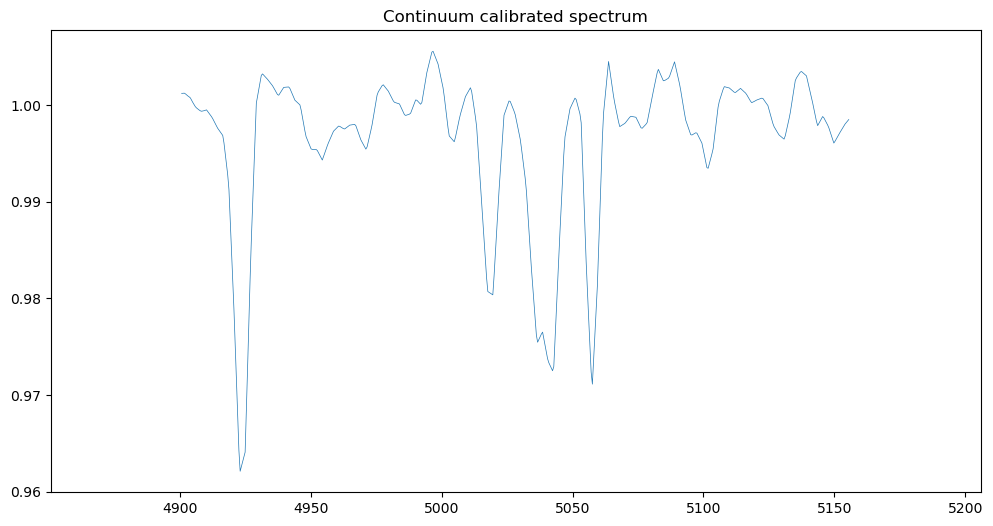

Unknown 5032 (gauss)
amp = -0.01680295239648035 
mu = 5034.999999999999 
sigma = 2.5329177172640507 
offset = 1.0 
chi2 = 0.010232301767545665


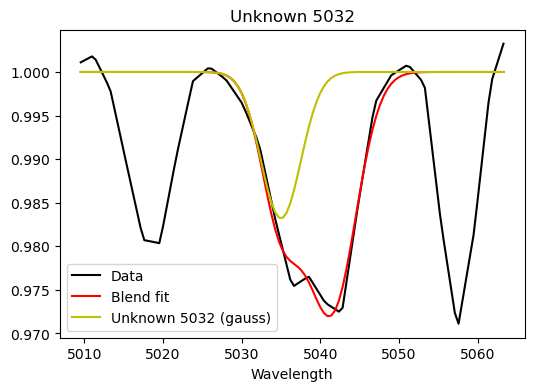

Si II 5041 (gauss)
amp = -0.027253161183610528 
mu = 5041.407604172575 
sigma = 3.105097356863307 
offset = 1.0 
chi2 = 0.010232301767545665


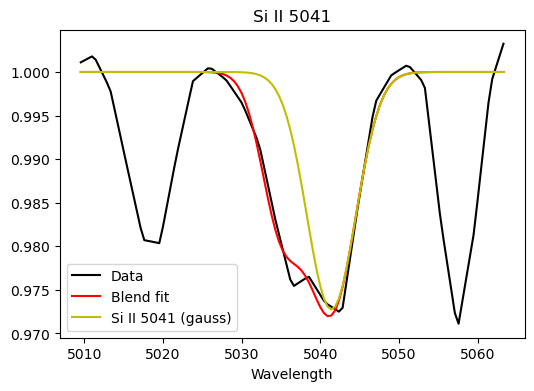

### Measuring He I 4713

Blended lines= [{'name': 'Unknown 4707', 'wavelength': 4707.0}, {'name': 'He I 4713', 'wavelength': 4713.0}]


#### He I 4713 preliminary fit

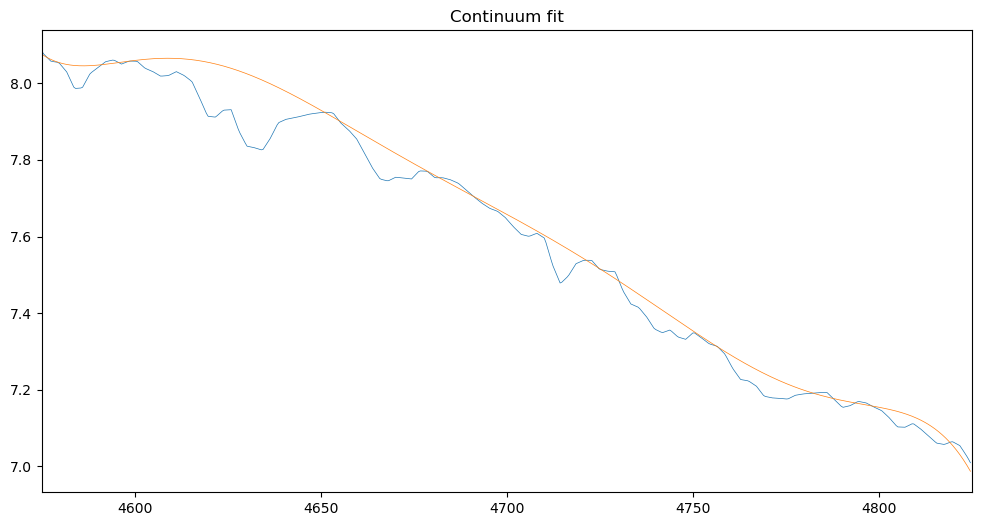

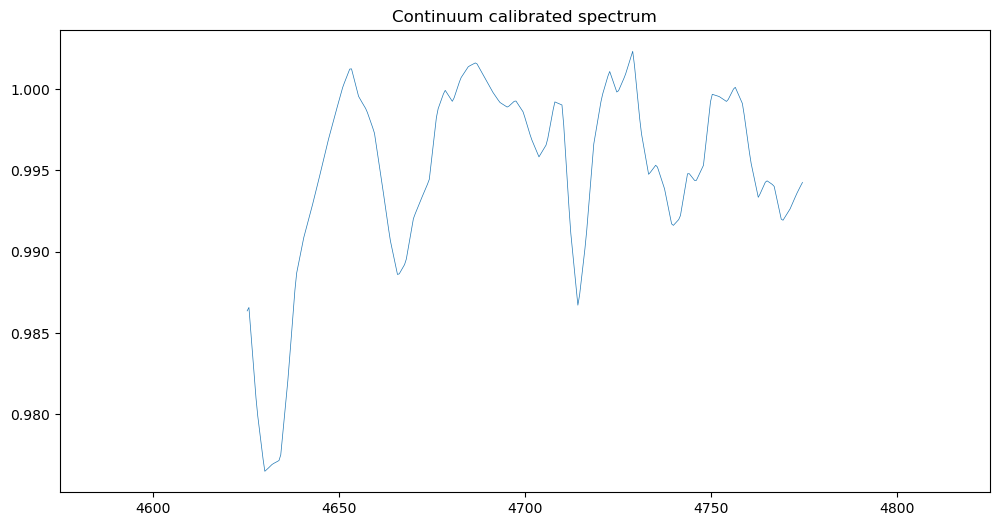

Fit window = (4688.2, 4731.8)
Unknown 4707 (gauss)
amp = -0.004080053280356501 
mu = 4704.000000000001 
sigma = 2.667023292549769 
offset = 1.0 
chi2 = 5.351493165802187e-05


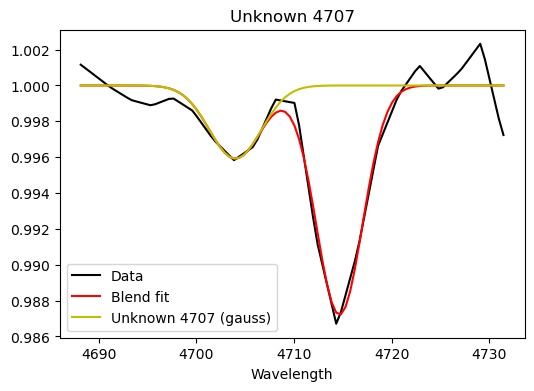

He I 4713 (gauss)
amp = -0.012794594677719802 
mu = 4714.6481930279115 
sigma = 2.364435416108234 
offset = 1.0 
chi2 = 5.351493165802187e-05


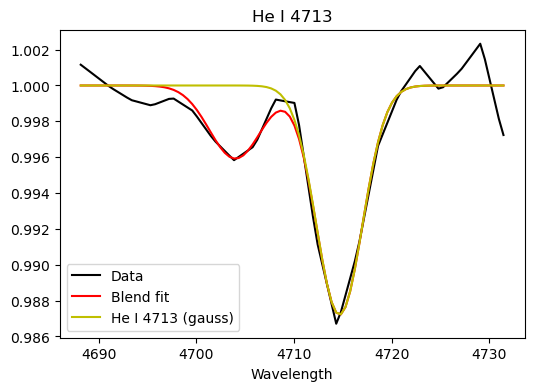

#### He I 4713 optimization

#### Plotting results for Unknown 4707

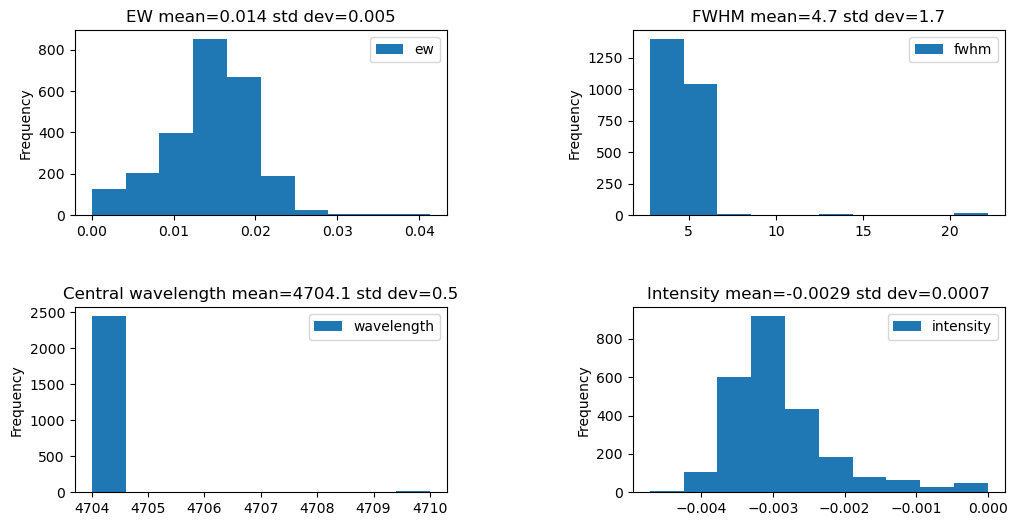

#### Plotting results for He I 4713

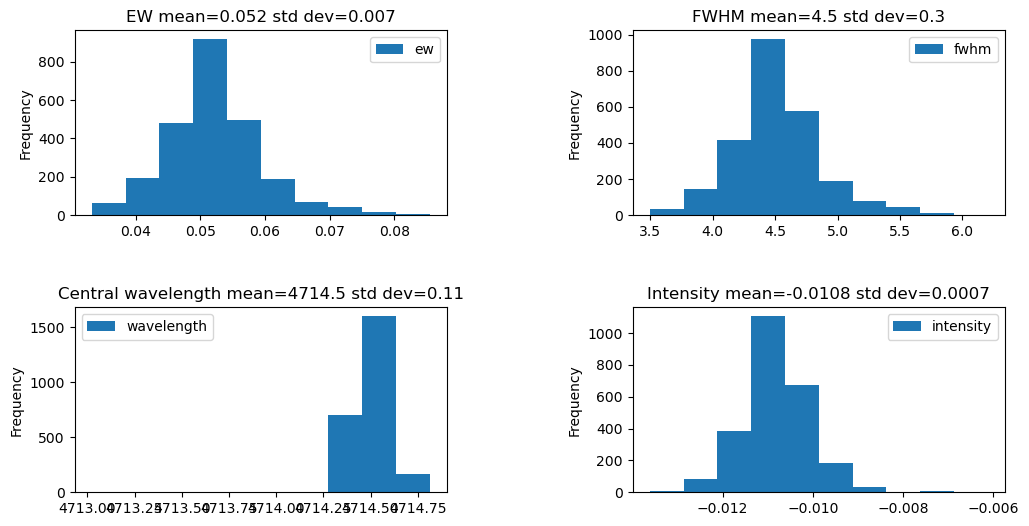

#### He I 4713 re-fit with best parameters

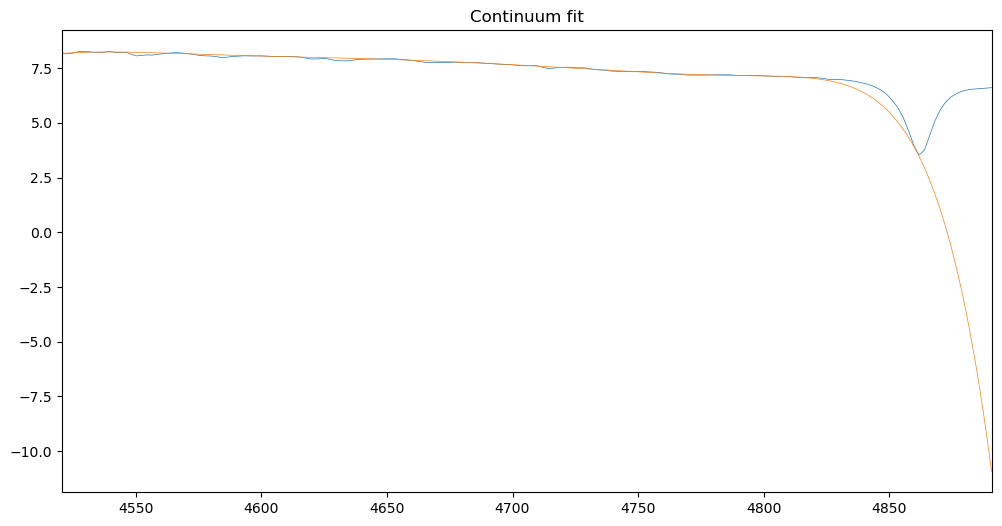

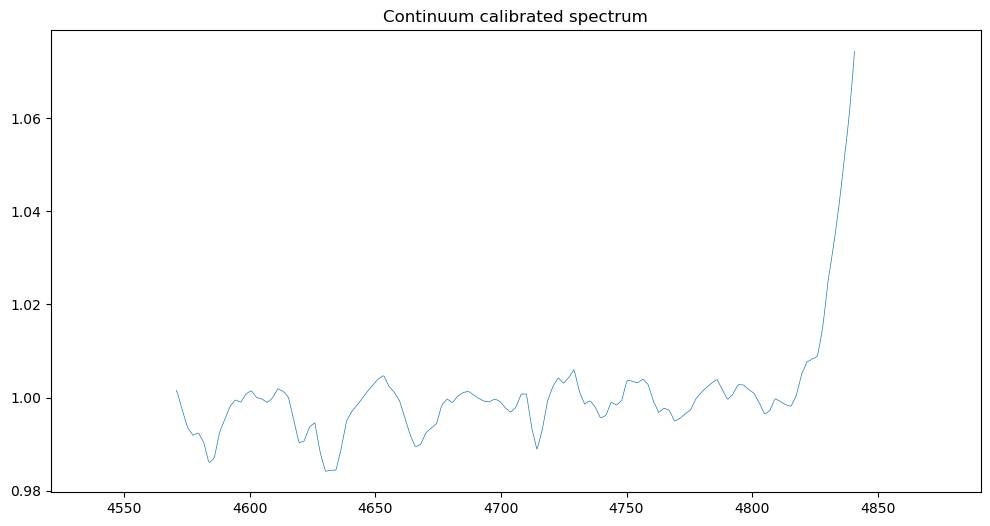

Unknown 4707 (gauss)
amp = -0.0031481589393568244 
mu = 4704.000000000001 
sigma = 2.0057096449076663 
offset = 1.0 
chi2 = 0.00039442694731645745


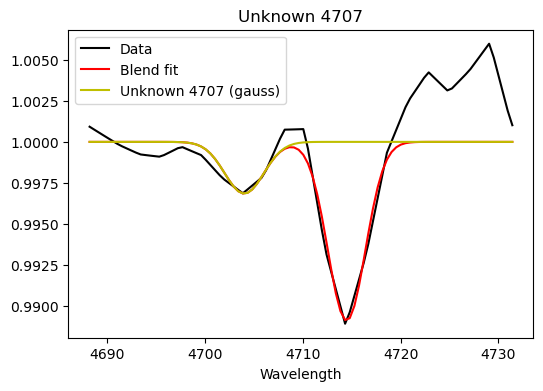

He I 4713 (gauss)
amp = -0.010885231249750398 
mu = 4714.477772993045 
sigma = 1.9191608194246468 
offset = 1.0 
chi2 = 0.00039442694731645745


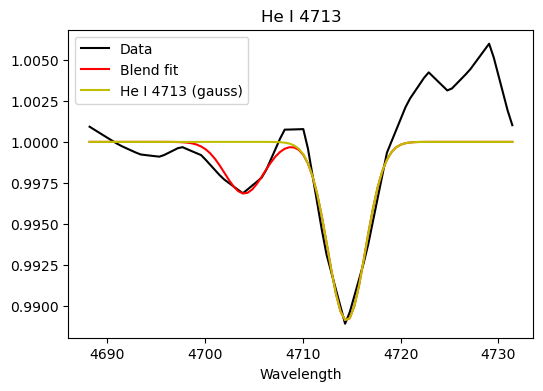

In [32]:
for measuring_blend in measuring_blends:
    results = measure_blend(wl, flux, measuring_blend, show_param_dependencies=SHOW_PARAM_DEPENDENCIES)
    summary_results = pd.concat([summary_results, results], axis=0)

## Summary Results

In [33]:
summary_results = summary_results.sort_values(by=["wavelength"], ascending=False)

summary_results


,line_name,wavelength,delta_wavelength,ew,delta_ew,fwhm,delta_fwhm,intensity,delta_intensity
0,H alfa,6564.386863,0.109794,9.146479,0.790118,16.084099,1.385769,-0.362018,0.000795
4,Si II 6371,6373.168767,0.061925,0.135774,0.008872,5.343404,0.214107,-0.023862,0.001013
3,Si II 6347,6348.933584,0.052022,0.212944,0.010429,5.894807,0.188132,-0.033929,0.000953
2,Si II 5056,5057.479817,0.038489,0.142343,0.015364,4.743876,0.307224,-0.028119,0.001165
1,Si II 5041,5041.321018,0.395574,0.215531,0.047435,7.629773,1.99189,-0.026633,0.000915
0,Unknown 5032,5034.531364,1.610356,0.112858,0.043714,7.195897,4.826647,-0.015797,0.001997
6,He I 4922,4923.513582,0.036193,0.253375,0.010967,6.210907,0.176916,-0.038313,0.000607
1,H beta,4862.096395,0.009518,9.08775,0.132109,13.394647,0.011536,-0.470868,0.001712
1,He I 4713,4714.499352,0.110288,0.05214,0.007175,4.512842,0.345816,-0.010811,0.000737
0,Unknown 4707,4704.058965,0.539267,0.014428,0.005427,4.65133,1.691791,-0.00289,0.000747


In [34]:
summary_results.to_csv("line_measured_phi_sgr_20250830.csv")